# Prédiction de la mortalité après un infarctus du myocarde

**Projet de Machine Learning** : Machine Learning / SDD / 3A FISE / ISAE-SUPAERO, année 2026-2027

| | |
|---|---|
| **Auteurs** | Luce Georgiou, Neel Alibert, Maxim Gasnier |
| **Données** | *Myocardial infarction complications* (Golovenkin *et al.*, 2020), 1 700 patients |
| **Tâche** | classification binaire supervisée : décès ou survie |

---

## Sommaire

0. [Introduction](#partie-0) : contexte, problématique, positionnement (IA, ML, DL), hypothèses, métrique, choix des algorithmes
1. [I - Chargement des données](#partie-I)
2. [II - Exploration des données](#partie-II) : cible, causes de décès, variables admission / jour 3, types, valeurs manquantes
3. [III - Séparation train / test et étude des variables discriminantes](#partie-III) : histogrammes, boxplots, corrélations
4. [IV - Feature engineering](#partie-IV) : création de nouvelles variables
5. [V - Preprocessing](#partie-V) : colonnes vides, imputation, standardisation, déséquilibre des classes
6. [VI - Exploration non supervisée](#partie-VI) : ACP (PCA) et clustering (k-means)
7. [VII - Apprentissage et réglage des hyperparamètres](#partie-VII) : validation croisée, modèles de référence, XGBoost, SVM
8. [VIII - Évaluation sur le jeu de test (scénario Admission)](#partie-VIII) : seuil de décision, matrices de confusion, ROC
9. [IX - Scénario Jour 3](#partie-IX) : apport des 3 premiers jours, importance des variables
10. [X - Analyse des faux négatifs](#partie-X)
11. [XI - Conclusion et perspectives](#partie-XI)

## <a id="partie-0"></a>0 - Introduction

### 0.1 - Contexte

Après un infarctus du myocarde, l'état d'un patient peut évoluer vers de nombreuses complications (troubles du rythme, œdème pulmonaire, choc cardiogénique, rupture myocardique, etc.). Savoir tôt quels patients sont à haut risque de décès permet aux cliniciens d'orienter la surveillance et les ressources vers ceux qui en ont le plus besoin.

Nous travaillons sur le jeu de données public **Myocardial infarction complications**, collecté à l'hôpital clinique interdistrict n° 20 de Krasnoïarsk (Russie) entre 1992 et 1995, et utilisé dans l'article suivant :

> Golovenkin S.E., Bac J., Chervov A., Mirkes E.M., Orlova Y.V., Barillot E., Gorban A.N., Zinovyev A. (2020). *Trajectories, bifurcations and pseudotime in large clinical datasets: applications to myocardial infarction and diabetes data.* arXiv:2007.03788.

Il contient **1 700 patients**, **111 variables d'entrée** (*features*) et **12 complications** possibles. Les variables d'entrée sont de types variés (binaires, ordinales, continues) et comportent de nombreuses **valeurs manquantes**.

### 0.2 - Problématique

> **Peut-on prédire le décès d'un patient après un infarctus, à partir de son admission, puis après 3 jours de soins ? Les informations recueillies pendant ces 3 jours améliorent-elles la prédiction ?**

Il s'agit d'un problème d'**apprentissage supervisé** (*supervised learning*) : pour chaque patient, on connaît l'issue réelle, que le modèle apprend à prédire. On choisit de se restreindre à une **classification binaire** : la cible `y` vaut 0 si le patient survit et 1 s'il décède, quelle qu'en soit la cause.

### 0.3 - Hypothèses

- **H1** : certaines variables (âge, pression artérielle, marqueurs biologiques) se comportent différemment chez les patients décédés et chez les survivants, et suffisent à prédire le risque.
- **H2** : les variables du jour 3 apportent un gain de performance par rapport aux seules variables d'admission.
- **H3** : la classe « décès » étant minoritaire (environ 1 décès pour 5 survivants), il faut corriger ce déséquilibre pour que le modèle détecte les décès.

Ces trois hypothèses sont testées dans le notebook et font l'objet d'une réponse explicite en conclusion (partie XI).

### 0.4 - Deux scénarios pour éviter la fuite de données

On construit deux jeux de variables :

| Objet | Contenu |
|---|---|
| `y` | la cible : décès (1) ou survie (0) |
| `X_admission` | variables connues **à l'admission** |
| `X_jour3` | toutes les variables d'entrée, connues **au 3ᵉ jour** |

Nous séparons soigneusement les données disponibles à l'admission de celles disponibles après 3 jours pour éviter la **fuite de données** (*data leakage*) : utiliser au jour 0 une information qui n'existe qu'au jour 3 rendrait le modèle artificiellement bon, mais inutilisable en pratique. Pour la même raison, toutes les transformations apprises (suppression de colonnes, imputation, standardisation, choix du seuil) sont calculées **uniquement sur le jeu d'entraînement**, puis appliquées au jeu de test.

### 0.5 - Choix de la métrique

Nous nous concentrons sur le **recall** (sensibilité) de la classe « décès » pour limiter les **faux négatifs** : un faux négatif correspond à un décès que le modèle n'a pas vu venir, ce qui est l'erreur la plus préjudiciable dans notre étude. Comme on peut obtenir un recall de 100 % en déclarant tous les patients « à risque », on le complète par :
- la **précision** : part des alertes qui concernent réellement un décès (coût en fausses alertes) ;
- le **F1-score** : moyenne harmonique de la précision et du recall, utilisée pour régler les hyperparamètres ;
- l'**AUC** de la courbe ROC : capacité à classer les patients, indépendamment du seuil de décision.

L'*accuracy* n'est pas adaptée : un modèle qui prédit toujours « survie » aurait déjà environ 84 % d'accuracy tout en étant inutile.

### 0.6 - Choix des algorithmes

| Modèle | Rôle | Justification |
|---|---|---|
| `DummyClassifier` | référence naïve | mesure ce qu'obtient un modèle qui n'apprend rien : tout modèle utile doit faire mieux |
| Régression logistique | référence linéaire | modèle classique des scores de risque cliniques, simple et interprétable |
| **XGBoost** | modèle principal | gradient boosting d'arbres de décision  |
| **SVM** (`SVC`) | modèle concurrent | classifieur à vaste marge  |

## <a id="partie-I"></a>I - Chargement des données

### I.1 - Import des bibliothèques

Toutes les bibliothèques sont importées une seule fois ici. Les paramètres globaux (`SEED`, validation croisée `cv`) sont définis dans cette même cellule pour être identiques dans tout le notebook.

**Reproductibilité.** La cellule affiche les versions des bibliothèques. Les résultats commentés dans ce notebook correspondent à l'exécution enregistrée avec ces versions. XGBoost utilise un tirage aléatoire interne (`subsample`, `colsample_bytree`) dont l'implémentation varie d'une version à l'autre : avec une autre version, les hyperparamètres retenus et les scores peuvent varier de quelques points. Lors de nos essais avec deux versions de XGBoost, les conclusions principales sont restées les mêmes.

In [1]:
# --- Bibliothèques standard ---
import os
import warnings

# --- Calcul et données ---
import numpy as np
import pandas as pd

# --- Visualisation ---
import matplotlib.pyplot as plt

# --- Scikit-learn : séparation, validation croisée, tuning ---
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    cross_val_predict,
    cross_validate,
    RandomizedSearchCV,
    validation_curve,
)

# --- Scikit-learn : preprocessing ---
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# --- Scikit-learn : non supervisé (partie VI) ---
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# --- Modèles ---
from sklearn.dummy import DummyClassifier             # modèle de référence naïf (partie VII)
from sklearn.linear_model import LogisticRegression   # modèle de référence linéaire (partie VII)
from sklearn.svm import SVC
from xgboost import XGBClassifier

# --- Versions (pour la reproductibilité) ---
import sklearn
import xgboost

# --- Métriques ---
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
)

# --- Statistiques (tests univariés, parties III et IV) ---
from scipy.stats import mannwhitneyu

# --- Paramètres globaux, définis UNE SEULE FOIS pour tout le notebook ---
SEED = 42                      # reproductibilité : mêmes patients en train/test pour tout le groupe
N_SPLITS = 5                   # nombre de plis de la validation croisée
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

# Affichage
pd.set_option("display.max_columns", 120)
plt.rcParams["figure.dpi"] = 100
warnings.filterwarnings("ignore", category=FutureWarning)

print(f"Versions : numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")

Versions : numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.4.2


### I.2 - Chargement du fichier CSV

Le fichier doit se trouver à côté du notebook ou dans un dossier `data/`. Si le programme ne le trouve pas, il lève une erreur `FileNotFoundError` qui indique les chemins essayés.

On utilise `index_col="ID"` : la colonne `ID` identifie le patient, ce n'est pas une variable à donner au modèle. Les valeurs manquantes sont des **cases vides** dans le CSV, que pandas lit directement comme `NaN`.

In [2]:
NAME_FILES = "Myocardial_infarction_complications_Database.csv"
PATH_FILES = [NAME_FILES, os.path.join("data", NAME_FILES), os.path.join("..", "data", NAME_FILES)]

chemin = next((c for c in PATH_FILES if os.path.exists(c)), None)
if chemin is None:
    raise FileNotFoundError(
        f"{NAME_FILES} introuvable. Cherché dans : {PATH_FILES}. "
        "Copiez le CSV dans le dossier du notebook ou dans data/."
    )

df = pd.read_csv(chemin, index_col="ID")
print("Fichier chargé :", chemin)
print("Dimensions :", df.shape)   # attendu : (1700, 123) = 111 entrées + 12 complications

Fichier chargé : data/Myocardial_infarction_complications_Database.csv
Dimensions : (1700, 123)


## <a id="partie-II"></a>II - Exploration des données

### II.1 - Séparation des variables d'entrée et des complications

Les 12 dernières colonnes sont des **complications** (dont `LET_IS`, l'issue létale). Toutes les autres sont des variables d'entrée. On sélectionne les complications **par leur nom** et non par leur position : un décalage d'une colonne passerait inaperçu et pourrait glisser une complication dans `X`, ce qui serait une fuite de données.

In [3]:
COMPLICATIONS = [
    "FIBR_PREDS",  # fibrillation auriculaire
    "PREDS_TAH",   # tachycardie supraventriculaire
    "JELUD_TAH",   # tachycardie ventriculaire
    "FIBR_JELUD",  # fibrillation ventriculaire
    "A_V_BLOK",    # bloc auriculo-ventriculaire du 3e degré
    "OTEK_LANC",   # œdème pulmonaire
    "RAZRIV",      # rupture myocardique
    "DRESSLER",    # syndrome de Dressler
    "ZSN",         # insuffisance cardiaque chronique
    "REC_IM",      # récidive d'infarctus
    "P_IM_STEN",   # angine post-infarctus
    "LET_IS",      # issue létale : 0 = survie, 1 à 7 = cause du décès
]

# Variables d'entrée
X_all = df.drop(columns=COMPLICATIONS)

print(f"Variables d'entrée : {X_all.shape[1]}  |  Complications : {len(COMPLICATIONS)}  |  Patients : {X_all.shape[0]}")

Variables d'entrée : 111  |  Complications : 12  |  Patients : 1700


### II.2 - Création de la cible

`LET_IS` vaut 0 si le patient survit, et de 1 à 7 selon la cause du décès (1 choc cardiogénique, 2 œdème pulmonaire, 3 rupture myocardique, 4 aggravation de l'insuffisance cardiaque, 5 thromboembolie, 6 asystolie, 7 fibrillation ventriculaire).

On choisit de **binariser** la variable (0 = survie, 1 = décès) afin d'obtenir un problème de classification binaire.

Répartition de la cible
deces
survie    1429
décès      271
Name: count, dtype: int64
Proportion de décès : 15.9%
Ratio : 1 décès pour 5.3 survivants
Accuracy d'un modèle qui prédit toujours « survie » : 84.1%


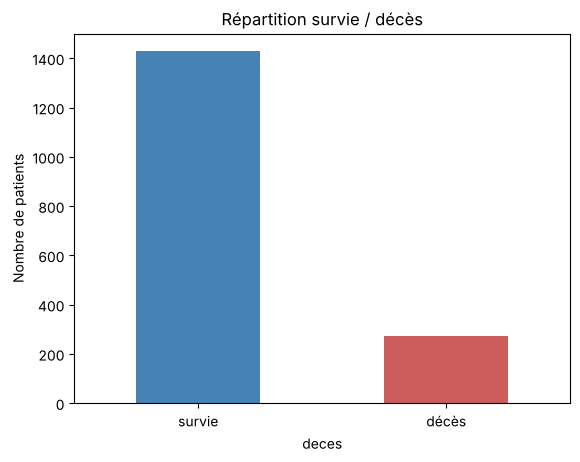

In [4]:
y = (df["LET_IS"] > 0).astype(int).rename("deces")

LABELS = {0: "survie", 1: "décès"}
repartition = y.value_counts().sort_index().rename(LABELS)

print("Répartition de la cible")
print(repartition)
print("Proportion de décès :", f"{y.mean():.1%}")
print(f"Ratio : 1 décès pour {repartition['survie'] / repartition['décès']:.1f} survivants")
print(f"Accuracy d'un modèle qui prédit toujours « survie » : {1 - y.mean():.1%}")

repartition.plot(kind="bar", color=["steelblue", "indianred"])
plt.title("Répartition survie / décès")
plt.ylabel("Nombre de patients")
plt.xticks(rotation=0)
plt.show()

**Interprétation.** La classe « décès » est minoritaire : 271 décès sur 1 700 patients (15,9 %), soit environ 1 décès pour 5,3 survivants. Un modèle qui prédirait toujours « survie » aurait déjà 84,1 % d'*accuracy* tout en ne détectant aucun décès. C'est pourquoi nous suivons le **recall** de la classe « décès » (ne pas rater de décès) plutôt que l'accuracy, et pourquoi le déséquilibre devra être corrigé (hypothèse H3, partie V.4).

### II.3 - Causes de décès

Avant de binariser, on regarde la répartition des causes de décès (`LET_IS` de 1 à 7). Elle permet de savoir quels mécanismes notre classe « décès » regroupe.

                                         patients  % des décès
LET_IS                                                        
Choc cardiogénique                            110         40.6
Rupture myocardique                            54         19.9
Fibrillation ventriculaire                     27         10.0
Asystolie                                      27         10.0
Aggravation de l'insuffisance cardiaque        23          8.5
Œdème pulmonaire                               18          6.6
Thromboembolie                                 12          4.4


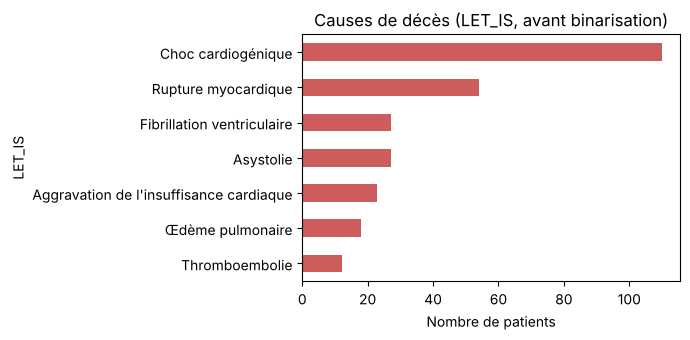

In [5]:
CAUSES_DECES = {
    1: "Choc cardiogénique", 2: "Œdème pulmonaire", 3: "Rupture myocardique",
    4: "Aggravation de l'insuffisance cardiaque", 5: "Thromboembolie",
    6: "Asystolie", 7: "Fibrillation ventriculaire",
}

causes = df.loc[df["LET_IS"] > 0, "LET_IS"].map(CAUSES_DECES).value_counts()
print(pd.DataFrame({"patients": causes, "% des décès": (causes / causes.sum() * 100).round(1)}).to_string())

causes.sort_values().plot(kind="barh", color="indianred", figsize=(7, 3.5))
plt.xlabel("Nombre de patients")
plt.title("Causes de décès (LET_IS, avant binarisation)")
plt.tight_layout()
plt.show()

**Interprétation.** Le choc cardiogénique est de loin la première cause de décès (110 patients, 41 % des décès), suivi de la rupture myocardique (54 patients, 20 %). Les cinq autres causes représentent chacune 10 % des décès ou moins. La classe « décès » regroupe donc des mécanismes très différents : un choc cardiogénique s'installe souvent progressivement et laisse des signes mesurables (pression artérielle basse, `K_SH_POST`), alors qu'une rupture myocardique ou une fibrillation ventriculaire sont des événements brutaux, plus difficiles à anticiper. C'est une première raison de penser que certains décès resteront difficiles à prédire (partie X). L'article de référence retrouve cette diversité : en regroupant les combinaisons de complications, il obtient 11 classes, dont 7 classes létales correspondant chacune à une cause de décès.

### II.4 - Séparation des variables disponibles à l'admission et après 3 jours

Pour savoir si la prédiction du décès est meilleure avec les données recueillies pendant les 3 premiers jours, nous construisons deux jeux de variables. Le premier contient uniquement les données disponibles à l'admission ; le second contient en plus les données des 3 premiers jours.

| Groupe | Colonnes | Moment où l'information existe |
|---|---|---|
| Antécédents, ECG, biologie, délai | `AGE` … `TIME_B_S` | à l'admission |
| Traitements de l'équipe de cardiologie d'urgence | `NA_KB`, `NOT_NA_KB`, `LID_KB` | avant l'arrivée à l'hôpital |
| Douleur récurrente | `R_AB_1_n`, `R_AB_2_n`, `R_AB_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 |
| Opioïdes en soins intensifs | `NA_R_1_n`, `NA_R_2_n`, `NA_R_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 |
| Anti-inflammatoires (AINS) en soins intensifs | `NOT_NA_1_n`, `NOT_NA_2_n`, `NOT_NA_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 |
| Autres traitements en soins intensifs | `NITR_S`, `LID_S_n`, `B_BLOK_S_n`, `ANT_CA_S_n`, `GEPAR_S_n`, `ASP_S_n`, `TIKL_S_n`, `TRENT_S_n` | pendant le séjour en soins intensifs (moment exact non précisé) |

**Règle officielle et choix prudent.** La description du jeu de données (Golovenkin *et al.*) n'interdit à l'admission que les 9 colonnes `R_AB_*`, `NA_R_*` et `NOT_NA_*`. Les 8 traitements en soins intensifs de la dernière ligne sont autorisés par cette règle, mais leur moment exact n'est pas précisé : un traitement décidé parce que l'état du patient s'aggrave « trahirait » l'issue. Par exemple, parmi les patients ayant reçu des nitrates liquides en soins intensifs (`NITR_S`), 37 % sont décédés, contre 13 % chez les autres. Par prudence, avec `STRICT_ADMISSION = True`, nous retirons aussi ces 8 colonnes du scénario Admission. Passer `STRICT_ADMISSION = False` reproduit exactement la règle officielle.

In [6]:
# Colonnes dont la valeur dépend de ce qui se passe APRÈS l'arrivée (jours 1 à 3)
COLONNES_APRES_ADMISSION = [
    "R_AB_1_n", "R_AB_2_n", "R_AB_3_n",          # récidive de la douleur
    "NA_R_1_n", "NA_R_2_n", "NA_R_3_n",          # opioïdes en soins intensifs
    "NOT_NA_1_n", "NOT_NA_2_n", "NOT_NA_3_n",    # anti-inflammatoires en soins intensifs
]

# Traitements en soins intensifs dont le moment exact est incertain.
# Si STRICT_ADMISSION = True, on les retire aussi du scénario « admission ».
COLONNES_SOINS_INTENSIFS_INCERTAINES = [
    "NITR_S",   # nitrates liquides en soins intensifs (colonne 99 de la description officielle)
    "LID_S_n", "B_BLOK_S_n", "ANT_CA_S_n", "GEPAR_S_n", "ASP_S_n", "TIKL_S_n", "TRENT_S_n",
]

STRICT_ADMISSION = True

a_retirer = list(COLONNES_APRES_ADMISSION)
if STRICT_ADMISSION:
    a_retirer += COLONNES_SOINS_INTENSIFS_INCERTAINES

On construit les deux jeux de variables :
- `X_jour3` : toutes les variables d'entrée (information complète au 3ᵉ jour) ;
- `X_admission` : les mêmes, moins les colonnes de la cellule précédente.

On garde des **DataFrames** (avec les noms de colonnes) plutôt que des tableaux numpy, pour pouvoir interpréter les résultats (importance des variables, analyse des erreurs).

In [7]:
X_jour3 = X_all.copy()
X_admission = X_all.drop(columns=a_retirer)

print("X_jour3     :", X_jour3.shape)
print("X_admission :", X_admission.shape)
print("Colonnes retirées pour l'admission :", len(a_retirer))

X_jour3     : (1700, 111)
X_admission : (1700, 94)
Colonnes retirées pour l'admission : 17


### II.5 - Types des variables et valeurs manquantes par colonne

On attribue un type à chacune des variables qui serviront à entraîner le modèle, car le traitement des valeurs manquantes et la standardisation en dépendent. On distingue 3 types :
- `binaire` : au plus 2 valeurs distinctes ;
- `ordinale` : des valeurs entières, au plus 10 modalités distinctes (seuil `SEUIL_ORDINALE`) ;
- `continue` : toutes les autres.

On calcule également le pourcentage de valeurs manquantes de chaque colonne. Le détail par type peut être affiché en passant `affichage = True`.

type
binaire     78
ordinale    21
continue    12
Name: count, dtype: int64

Variables continues : ['AGE', 'S_AD_KBRIG', 'D_AD_KBRIG', 'S_AD_ORIT', 'D_AD_ORIT', 'K_BLOOD', 'NA_BLOOD', 'ALT_BLOOD', 'AST_BLOOD', 'KFK_BLOOD', 'L_BLOOD', 'ROE']

Colonnes sans aucune valeur manquante : 1 sur 111
Colonnes avec plus de 40 % de valeurs manquantes : 5


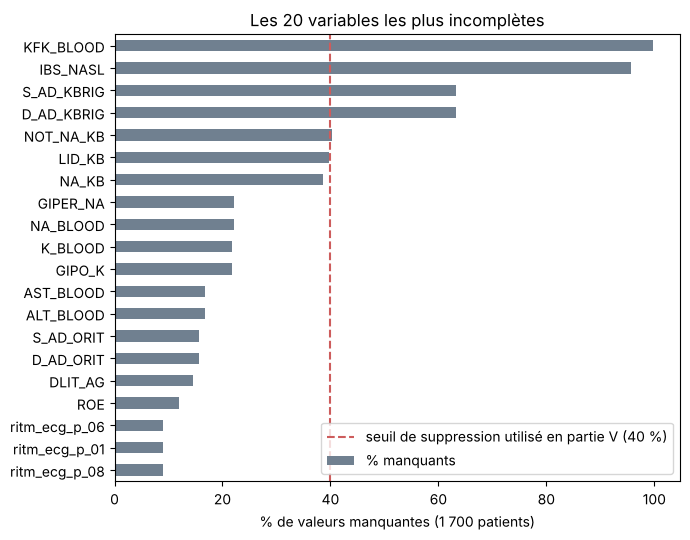

In [8]:
SEUIL_ORDINALE = 10  # au plus 10 modalités entières distinctes -> ordinale

def type_variable(s):
    """Classe une colonne en 'binaire', 'ordinale' ou 'continue' (NaN ignorés)."""
    valeurs = s.dropna().unique()
    if len(valeurs) <= 2:
        return "binaire"
    if np.all(valeurs == np.round(valeurs)) and len(valeurs) <= SEUIL_ORDINALE:
        return "ordinale"
    return "continue"

def resume_par_type(X):
    return pd.DataFrame({
        "type": X.apply(type_variable),
        "nb_modalites": X.nunique(),
        "min": X.min(),
        "max": X.max(),
        "moyenne": X.mean(),
        "% manquants": X.isna().mean() * 100,
    })

resume_all = resume_par_type(X_all)

print(resume_all["type"].value_counts())
print("\nVariables continues :", resume_all.index[resume_all["type"] == "continue"].tolist())

affichage = False   # True : affiche le tableau détaillé de chaque type

if affichage:
    for t in ["binaire", "ordinale", "continue"]:
        print(f"\n=== Variables {t}s ===")
        display(resume_all[resume_all["type"] == t].drop(columns="type"))

# Pourcentage de valeurs manquantes par colonne : les 20 colonnes les plus incomplètes
na_colonnes = resume_all["% manquants"].sort_values(ascending=False)
print(f"\nColonnes sans aucune valeur manquante : {(na_colonnes == 0).sum()} sur {len(na_colonnes)}")
print(f"Colonnes avec plus de 40 % de valeurs manquantes : {(na_colonnes > 40).sum()}")

na_colonnes.head(20).sort_values().plot(kind="barh", figsize=(7, 5.5), color="slategray")
plt.axvline(40, color="indianred", linestyle="--", lw=1.5, label="seuil de suppression utilisé en partie V (40 %)")
plt.xlabel("% de valeurs manquantes (1 700 patients)")
plt.title("Les 20 variables les plus incomplètes")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interprétation.** Le jeu de données est très majoritairement **qualitatif** : 78 variables binaires et 21 ordinales, pour seulement 12 variables continues (âge, pressions artérielles, biologie). Une seule colonne sur 111 est complète. Cinq colonnes dépassent 40 % de valeurs manquantes : `KFK_BLOOD` (enzyme cardiaque, presque jamais renseignée), `IBS_NASL` (antécédents familiaux de maladie coronarienne), les pressions mesurées par l'équipe d'urgence (`S_AD_KBRIG`, `D_AD_KBRIG`, environ 63 %) et `NOT_NA_KB`. Les trois traitements de l'équipe d'urgence (`NA_KB`, `NOT_NA_KB`, `LID_KB`) manquent pour les mêmes patients (environ 37 % du total), vraisemblablement ceux qui n'ont pas été pris en charge par cette équipe. Une valeur manquante peut donc être **informative**, ce qu'il faudrait confirmer avec les cliniciens (partie XI).

### II.6 - Valeurs manquantes par patient

On calcule maintenant le pourcentage de valeurs manquantes de chaque patient (chaque ligne de `X_all`), pour savoir si certains dossiers sont trop incomplets pour être exploités.

Pourcentage de valeurs manquantes par patient
  Moyenne    : 8.5 %
  Médiane    : 6.3 %
  Minimum    : 0.9 %
  Maximum    : 54.0 %
Patients avec plus de 10 % de valeurs manquantes : 373 (21.9%)
Patients avec plus de 20 % de valeurs manquantes : 140 (8.2%)
Patients avec plus de 30 % de valeurs manquantes : 62 (3.6%)
Patients avec plus de 40 % de valeurs manquantes : 4 (0.2%)


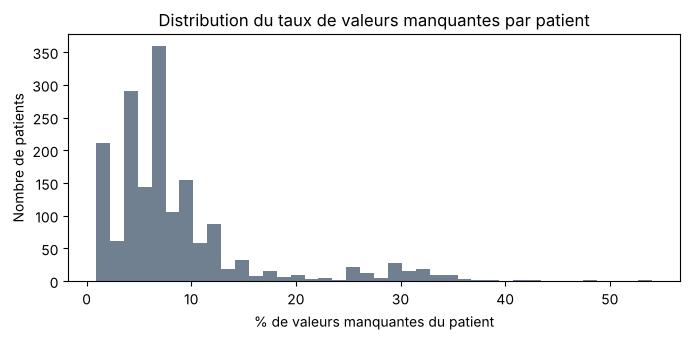

In [9]:
# Pourcentage de valeurs manquantes pour chaque patient (chaque ligne de X_all)
resume_patient = (
    X_all.isna().mean(axis=1)
    .mul(100)
    .round(2)
    .rename("% manquants")
    .to_frame()
)

# Résumé statistique du % de valeurs manquantes par patient
print("Pourcentage de valeurs manquantes par patient")
print(f"  Moyenne    : {resume_patient['% manquants'].mean():.1f} %")
print(f"  Médiane    : {resume_patient['% manquants'].median():.1f} %")
print(f"  Minimum    : {resume_patient['% manquants'].min():.1f} %")
print(f"  Maximum    : {resume_patient['% manquants'].max():.1f} %")

# Nombre de patients au-dessus de quelques seuils
for seuil in (10, 20, 30, 40):
    n = (resume_patient["% manquants"] > seuil).sum()
    print(f"Patients avec plus de {seuil} % de valeurs manquantes : {n} ({n / len(resume_patient):.1%})")

resume_patient["% manquants"].plot(kind="hist", bins=40, color="slategray", figsize=(7, 3.5))
plt.xlabel("% de valeurs manquantes du patient")
plt.ylabel("Nombre de patients")
plt.title("Distribution du taux de valeurs manquantes par patient")
plt.tight_layout()
plt.show()

**Interprétation.** Les dossiers sont globalement bien remplis : un patient a en moyenne 8,5 % de valeurs manquantes (médiane 6,3 %), et 78 % des patients en ont moins de 10 %. La distribution a cependant une longue queue : 140 patients (8,2 %) dépassent 20 % et 4 patients dépassent 40 % (au maximum 54 %). Nous choisissons de **conserver tous les patients** : supprimer des lignes réduirait encore le petit nombre de décès, et les valeurs manquantes seront traitées colonne par colonne (partie V).

## <a id="partie-III"></a>III - Séparation train / test et étude des variables discriminantes

On sépare les patients en un jeu d'entraînement et un jeu de test **avant** toute étude approfondie des variables : les graphiques de cette partie servent à prendre des décisions (choix de variables, feature engineering), et les faire sur le jeu de test fausserait l'évaluation finale.

### III.1 - Séparation train / test

In [10]:
# 1. On sépare les PATIENTS (leurs identifiants), pas les tableaux.
#    Ainsi X_admission et X_jour3 ont exactement les mêmes patients de test.
idx_train, idx_test = train_test_split(
    y.index,
    test_size=0.2,    # 20 % des patients pour le test
    stratify=y,       # même proportion de décès dans le train et le test
    random_state=SEED,
)

# 2. On applique ce découpage aux deux scénarios et à la cible
X_adm_train, X_adm_test = X_admission.loc[idx_train], X_admission.loc[idx_test]
X_j3_train,  X_j3_test  = X_jour3.loc[idx_train],     X_jour3.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# 3. Vérifications
print(f"Train : {len(idx_train)} patients, {y_train.sum()} décès ({y_train.mean():.1%})")
print(f"Test  : {len(idx_test)} patients, {y_test.sum()} décès ({y_test.mean():.1%})")

assert set(idx_train).isdisjoint(idx_test), "Des patients sont à la fois dans le train et le test"
assert X_adm_train.index.equals(X_j3_train.index) and X_adm_test.index.equals(X_j3_test.index)

Train : 1360 patients, 217 décès (16.0%)
Test  : 340 patients, 54 décès (15.9%)


La stratification conserve la même proportion de décès (environ 16 %) dans les deux jeux. Le jeu de test ne contient que 54 décès : il faudra garder en tête que chaque décès compte pour environ 2 points de recall.

### III.2 - Variables discriminantes : histogrammes et boxplots

Nous cherchons à savoir si certaines *features* se comportent différemment chez les patients décédés et chez les survivants (hypothèse H1). Pour neuf variables continues cliniquement importantes, nous traçons un **histogramme** (forme de la distribution) et un **boxplot** (médiane, quartiles et valeurs extrêmes), puis nous testons la différence entre les deux groupes avec un **test de Mann-Whitney** (test non paramétrique, adapté aux distributions asymétriques).

Trois choix méthodologiques :
- **Jeu d'entraînement uniquement**, pour ne pas utiliser le test dans nos décisions.
- **Histogrammes normalisés (densité)** : les décès sont 5 fois moins nombreux que les survies ; sans normalisation, leur distribution serait écrasée.
- **Effectif affiché** sur chaque graphique : la comparaison n'a de sens que si chaque groupe contient assez de patients renseignés.
- Les enzymes (KFK, ALT, AST) sont très asymétriques : on les affiche en échelle `log(1 + x)`.

% de valeurs manquantes (train) :
KFK_BLOOD     99.7
S_AD_KBRIG    63.5
AST_BLOOD     16.9
ALT_BLOOD     16.8
S_AD_ORIT     16.2
D_AD_ORIT     16.2
ROE           12.4
L_BLOOD        7.6
AGE            0.4


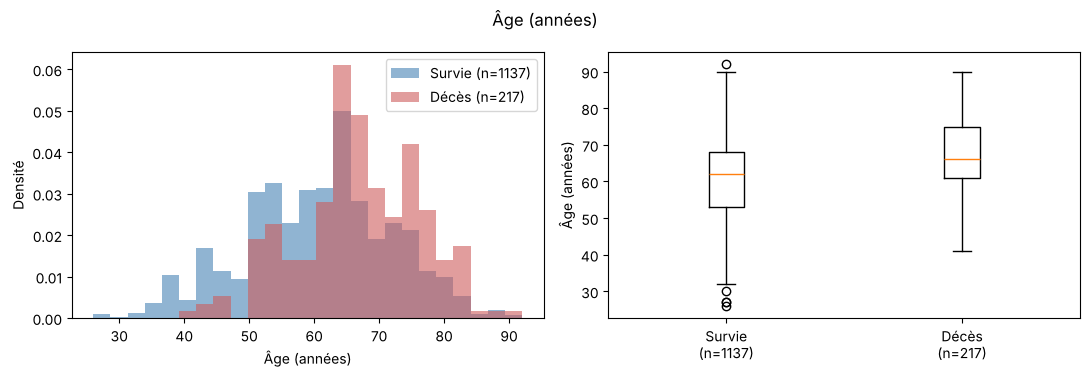

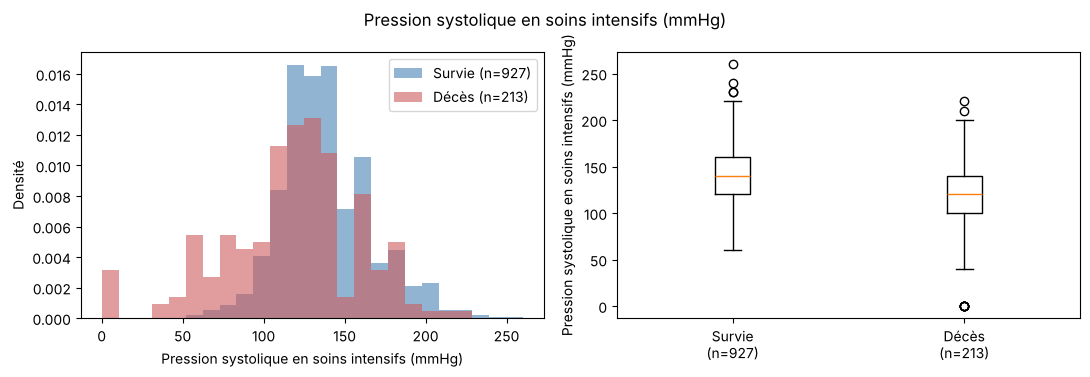

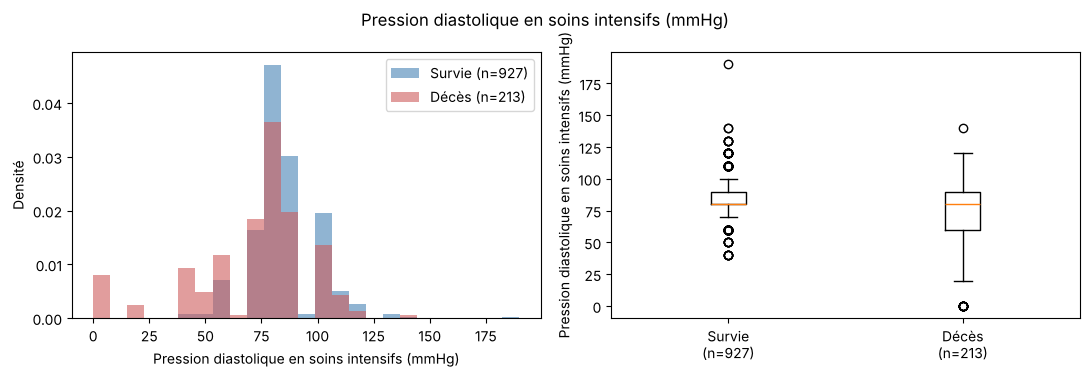

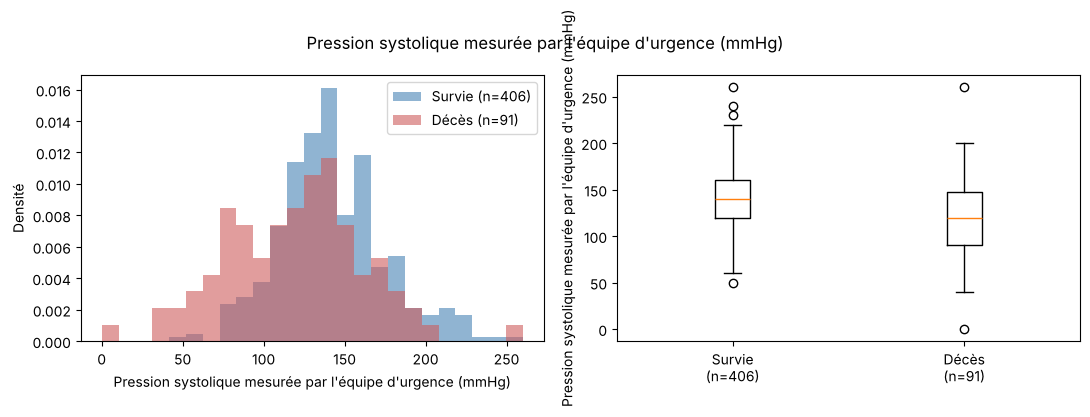

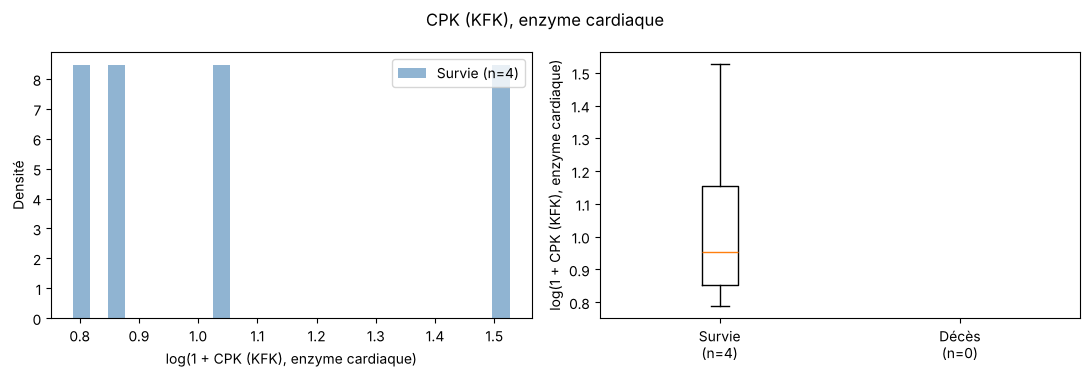

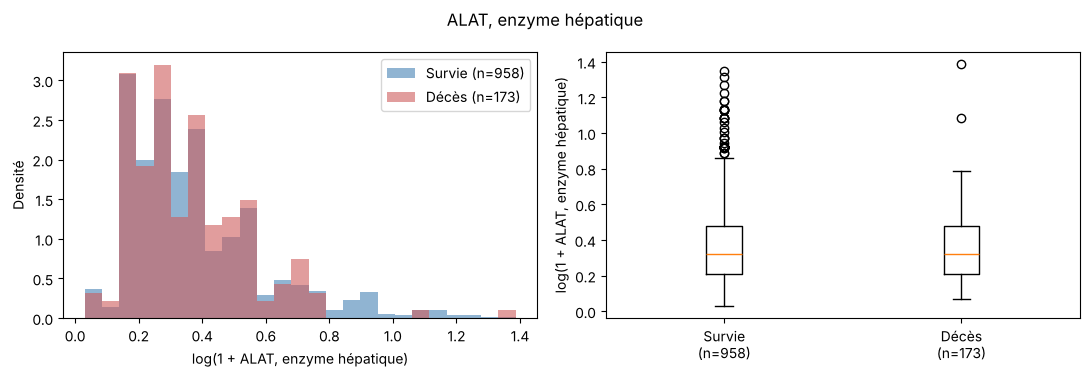

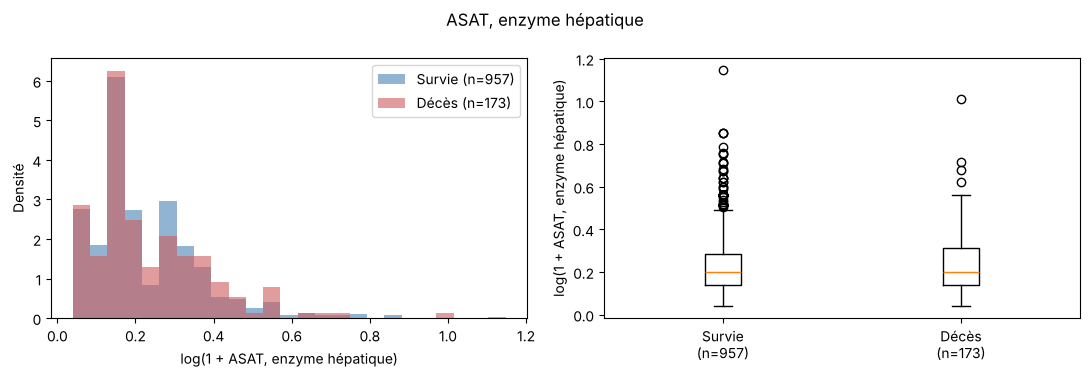

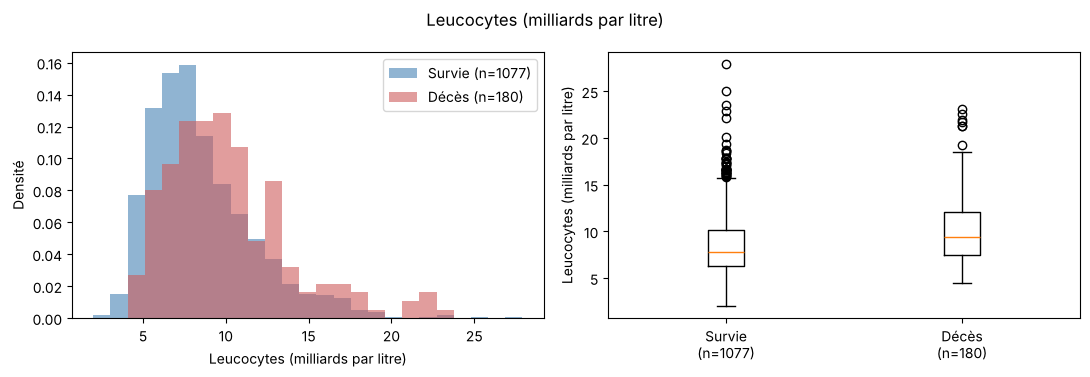

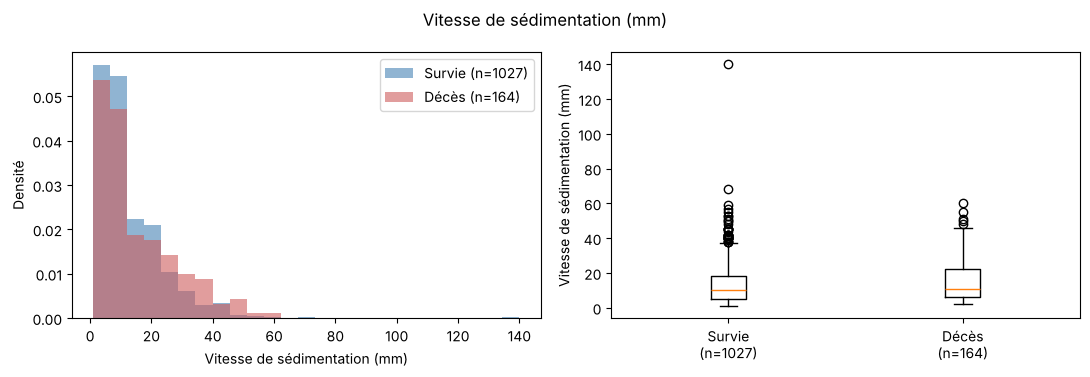

,n survie,n décès,médiane survie,médiane décès,p-value (Mann-Whitney)
variable,,,,,
AGE,1137,217,62.00,66.00,0.0000
S_AD_ORIT,927,213,140.00,120.00,0.0000
D_AD_ORIT,927,213,80.00,80.00,0.0000
S_AD_KBRIG,406,91,140.00,120.00,0.0000
KFK_BLOOD,4,0,1.60,NaN,NaN
ALT_BLOOD,958,173,0.38,0.38,0.6809
AST_BLOOD,957,173,0.22,0.22,0.9025
L_BLOOD,1077,180,7.80,9.40,0.0000
ROE,1027,164,10.00,11.00,0.0242


In [11]:
# Tableau d'exploration : variables du jour 3 + groupe (survie / décès), train uniquement
exploration = X_j3_train.copy()
exploration["groupe"] = y_train.map({0: "Survie", 1: "Décès"})

COULEURS = {"Survie": "steelblue", "Décès": "indianred"}

# colonne : (libellé, échelle logarithmique ?)
# Unités des enzymes à vérifier : les valeurs observées ne correspondent pas aux UI/L de la description.
VARIABLES = {
    "AGE":        ("Âge (années)", False),
    "S_AD_ORIT":  ("Pression systolique en soins intensifs (mmHg)", False),
    "D_AD_ORIT":  ("Pression diastolique en soins intensifs (mmHg)", False),
    "S_AD_KBRIG": ("Pression systolique mesurée par l'équipe d'urgence (mmHg)", False),
    "KFK_BLOOD":  ("CPK (KFK), enzyme cardiaque", True),
    "ALT_BLOOD":  ("ALAT, enzyme hépatique", True),
    "AST_BLOOD":  ("ASAT, enzyme hépatique", True),
    "L_BLOOD":    ("Leucocytes (milliards par litre)", False),
    "ROE":        ("Vitesse de sédimentation (mm)", False),
}

def comparer(col, libelle, log=False):
    """Histogramme + boxplot de `col`, survivants contre décédés."""
    donnees = {g: exploration.loc[exploration["groupe"] == g, col].dropna()
               for g in ["Survie", "Décès"]}
    if log:  # variables très asymétriques : on passe à log(1 + x) pour y voir quelque chose
        donnees = {g: np.log1p(v) for g, v in donnees.items()}
    xlabel = f"log(1 + {libelle})" if log else libelle

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

    # Histogramme : mêmes classes pour les deux groupes, et density=True car
    # les décès sont beaucoup moins nombreux (sinon leur barre serait invisible)
    tout = np.concatenate([v.values for v in donnees.values()])
    bins = np.histogram_bin_edges(tout, bins=25)
    for g, v in donnees.items():
        if len(v) == 0:   # aucun patient renseigné dans ce groupe (cas de la KFK chez les décédés)
            continue
        ax1.hist(v, bins=bins, density=True, alpha=0.6, color=COULEURS[g],
                 label=f"{g} (n={len(v)})")
    ax1.set_xlabel(xlabel); ax1.set_ylabel("Densité"); ax1.legend()

    # Boxplot avec l'effectif de chaque groupe
    ax2.boxplot([donnees["Survie"], donnees["Décès"]], showfliers=True)
    ax2.set_xticks([1, 2])
    ax2.set_xticklabels([f"{g}\n(n={len(donnees[g])})" for g in ["Survie", "Décès"]])
    ax2.set_ylabel(xlabel)

    fig.suptitle(libelle)
    plt.tight_layout()
    plt.show()

# 1. Regarder d'abord combien de valeurs manquantes (et donc combien de patients exploitables)
cols = list(VARIABLES)
print("% de valeurs manquantes (train) :")
print((exploration[cols].isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

# 2. Un couple de graphiques par variable
for col, (libelle, log) in VARIABLES.items():
    comparer(col, libelle, log)

# 3. Tableau récapitulatif : effectifs, médianes et test de Mann-Whitney par variable
lignes = []
for col in cols:
    surv = exploration.loc[exploration["groupe"] == "Survie", col].dropna()
    dec = exploration.loc[exploration["groupe"] == "Décès", col].dropna()
    p = mannwhitneyu(surv, dec).pvalue if min(len(surv), len(dec)) >= 5 else np.nan
    lignes.append({"variable": col, "n survie": len(surv), "n décès": len(dec),
                   "médiane survie": surv.median(), "médiane décès": dec.median(),
                   "p-value (Mann-Whitney)": p})
tableau_discriminant = pd.DataFrame(lignes).set_index("variable")
display(tableau_discriminant.round(4))

### Interprétation

**Valeurs manquantes.** Le pourcentage de valeurs manquantes varie fortement d'une variable à l'autre : 0,4 % pour l'âge, 7,6 % pour les leucocytes, 12 à 17 % pour la vitesse de sédimentation, les pressions en soins intensifs et les enzymes hépatiques, 63,5 % pour la pression mesurée par l'équipe d'urgence et 99,7 % pour la KFK. Une valeur manquante signifie souvent qu'un examen n'a pas été réalisé, et pas seulement qu'une saisie a été oubliée. Pour la KFK, seuls 4 patients sont renseignés dans le train, dont aucun décédé : la comparaison est impossible et nous ne l'interprétons pas.

**Âge.** Les patients décédés sont plus âgés que les survivants : l'âge médian est de 66 ans chez les décédés contre 62 ans chez les survivants (p < 0,001). Les deux distributions se chevauchent toutefois largement : l'âge ne suffit pas seul à prédire le décès, mais c'est une caractéristique intéressante pour notre modèle.

**Pression artérielle.** À l'entrée en soins intensifs, la pression systolique médiane est de 140 mmHg chez les survivants et de 120 mmHg chez les décédés (p < 0,001). L'histogramme montre surtout une **queue de pressions basses** occupée par les décès : dans le train, 42 des 57 patients ayant une systolique inférieure à 90 mmHg sont décédés (74 %). C'est la signature du choc cardiogénique, première cause de décès. Sept patients, tous décédés, ont une pression notée 0 mmHg, ce qui peut correspondre à un arrêt circulatoire ou à une convention de saisie (à vérifier avec les cliniciens). On retrouve le même écart de médianes (140 contre 120 mmHg) sur la pression mesurée par l'équipe d'urgence, mais elle n'est connue que pour un tiers des patients. La pression diastolique a la même médiane (80 mmHg) dans les deux groupes, mais une distribution plus étalée vers le bas chez les décédés (premier quartile à 60 mmHg contre 80 mmHg).

**KFK (enzyme cardiaque).** La KFK (CPK) est une enzyme libérée par le muscle cardiaque lorsqu'il est lésé : elle est généralement associée à l'étendue de la nécrose. La variable est renseignée pour trop peu de patients : elle n'est donc pas exploitable pour notre analyse et sera supprimée en partie V.

**ALAT et ASAT (enzymes).** Ces enzymes reflètent l'état du foie, mais l'ASAT augmente aussi lors de lésions cardiaques. Leurs distributions sont très proches chez les décédés et les survivants (mêmes médianes, p = 0,68 et p = 0,90) : prises isolément, ces variables ne sont pas discriminantes. Leur rapport sera testé en partie IV. Remarque : les valeurs observées (médiane d'environ 0,4 pour l'ALAT) ne correspondent pas aux UI/L annoncées par la description ; l'unité exacte serait à demander aux auteurs.

**Leucocytes.** Les leucocytes (globules blancs) augmentent en cas de réaction inflammatoire, dont la nécrose du muscle cardiaque. Le nombre médian est de 7,8 milliards par litre chez les survivants et de 9,4 chez les décédés (p < 0,001). Cette caractéristique est donc intéressante pour notre analyse.

**Vitesse de sédimentation (ROE).** L'écart est faible (médianes de 10 et 11 mm, p = 0,02) : variable peu discriminante.

**Valeurs extrêmes.** Nous avons pris la décision de ne pas supprimer les valeurs extrêmes, car elles peuvent correspondre à des cas réels de patients : une pression très basse est justement un signe de gravité. Les modèles à base d'arbres comme XGBoost y sont peu sensibles.

**Synthèse (premier élément de réponse à H1).**
- Les variables qui distinguent le mieux les deux groupes sont l'âge, la pression artérielle (systolique surtout) et les leucocytes.
- Les variables peu ou pas discriminantes sont l'ALAT, l'ASAT et la vitesse de sédimentation ; la KFK est inexploitable.
- Aucune variable ne sépare seule les deux groupes : les distributions se chevauchent toujours. Il faudra **combiner** les variables, ce qui justifie l'usage d'un modèle de machine learning.
- Une variable à créer lors du *feature engineering* : la pression pulsée (systolique − diastolique).

### III.3 - Matrice de corrélation

La **corrélation** mesure à quel point deux variables varient ensemble. On utilise la corrélation de **Spearman** (fondée sur les rangs), mieux adaptée que celle de Pearson à des variables binaires, ordinales ou asymétriques. Deux usages :
1. repérer les variables **redondantes** entre elles (corrélation forte) ;
2. repérer les variables les plus **liées à la cible** (premier indice pour H1).

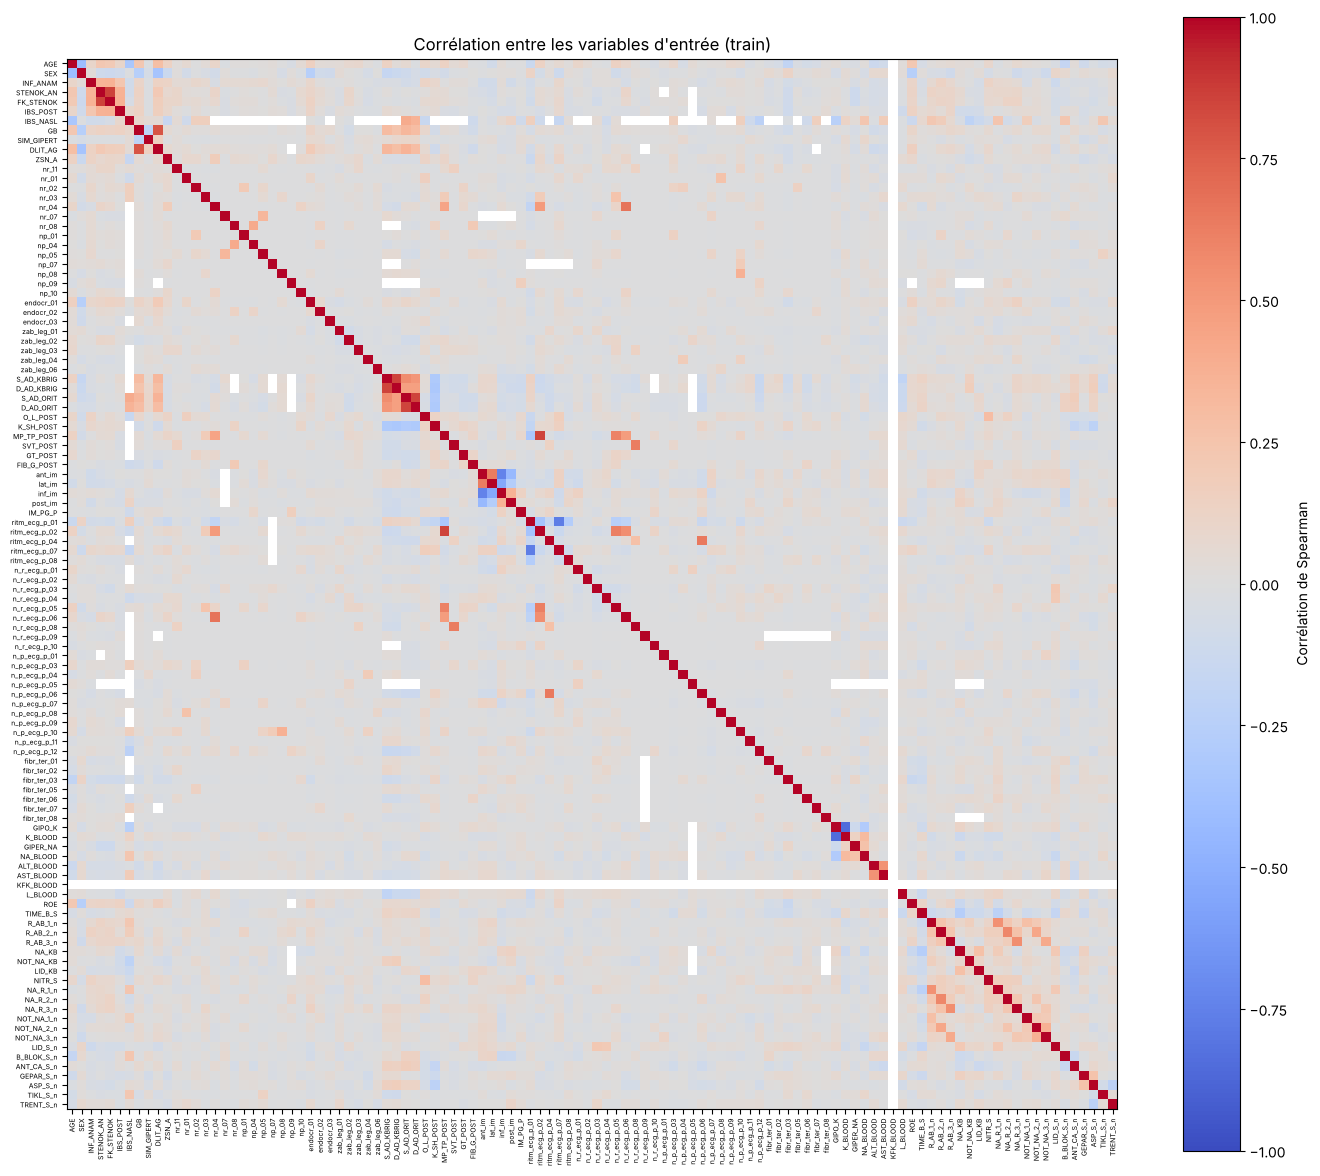

8 paires avec |corrélation| >= 0.7
STENOK_AN      FK_STENOK        0.86
S_AD_ORIT      D_AD_ORIT        0.85
GIPO_K         K_BLOOD         -0.85
S_AD_KBRIG     D_AD_KBRIG       0.84
MP_TP_POST     ritm_ecg_p_02    0.84
GB             DLIT_AG          0.79
ritm_ecg_p_01  ritm_ecg_p_07   -0.77
ant_im         inf_im          -0.74

15 variables les plus corrélées au décès :
K_SH_POST        0.362
ritm_ecg_p_01   -0.211
S_AD_KBRIG      -0.209
AGE              0.208
S_AD_ORIT       -0.203
D_AD_ORIT       -0.196
D_AD_KBRIG      -0.191
NITR_S           0.189
ASP_S_n         -0.181
STENOK_AN        0.178
n_p_ecg_p_12     0.177
L_BLOOD          0.174
O_L_POST         0.171
TIME_B_S        -0.171
R_AB_3_n         0.170


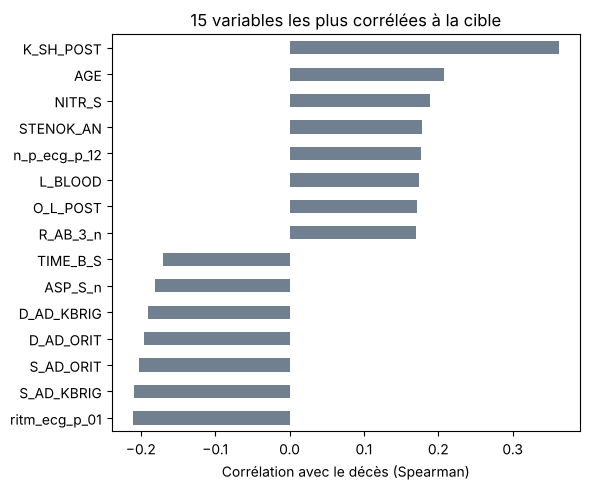

In [12]:
# 1. Données : toutes les features du jour 3, train uniquement.
#    On retire les colonnes constantes (une corrélation avec elles n'est pas définie).
donnees = X_j3_train.copy()
donnees = donnees.loc[:, donnees.nunique() > 1]

# 2. Matrice de corrélation de Spearman, calculée sur les patients où les deux variables sont connues.
#    min_periods : si moins de 30 patients ont les deux valeurs, la corrélation reste vide (NaN).
corr = donnees.corr(method="spearman", min_periods=30)

# 3. Heatmap
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=5)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=5)
fig.colorbar(im, ax=ax, label="Corrélation de Spearman")
ax.set_title("Corrélation entre les variables d'entrée (train)")
plt.tight_layout()
plt.show()

# 4. Paires de variables fortement corrélées (on ne garde que le triangle supérieur pour éviter les doublons)
SEUIL = 0.7
haut = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
paires = haut[haut.abs() >= SEUIL].sort_values(key=abs, ascending=False)
print(f"{len(paires)} paires avec |corrélation| >= {SEUIL}")
print(paires.round(2).to_string())

# 5. Corrélation de chaque variable avec la cible (décès)
avec_cible = donnees.apply(lambda col: col.corr(y_train, method="spearman", min_periods=30))
top = avec_cible.reindex(avec_cible.abs().sort_values(ascending=False).index).head(15)
print("\n15 variables les plus corrélées au décès :")
print(top.round(3).to_string())

top.sort_values().plot(kind="barh", figsize=(6, 5), color="slategray")
plt.xlabel("Corrélation avec le décès (Spearman)")
plt.title("15 variables les plus corrélées à la cible")
plt.tight_layout()
plt.show()

**Interprétation.**
- **Redondances.** Seules 8 paires de variables dépassent |0,7|, et elles s'expliquent toutes cliniquement : l'angine d'effort et sa classe fonctionnelle (`STENOK_AN` / `FK_STENOK`, 0,86), les pressions systolique et diastolique (0,85 en soins intensifs, 0,84 aux urgences), l'hypokaliémie et le potassium sanguin (`GIPO_K` / `K_BLOOD`, −0,85 : la première est un seuil appliqué au second), la fibrillation auriculaire observée à deux moments (`MP_TP_POST` / `ritm_ecg_p_02`, 0,84), l'hypertension et sa durée (`GB` / `DLIT_AG`, 0,79), deux types de rythme sinusal qui s'excluent (`ritm_ecg_p_01` / `ritm_ecg_p_07`, −0,77) et les localisations antérieure et inférieure de l'infarctus (−0,74). Ces redondances ne gênent pas XGBoost (un arbre utilise l'une ou l'autre), mais elles peuvent rendre instables les coefficients d'un modèle linéaire et répartir l'importance entre variables jumelles (IX.4). Nous les conservons.
- **Lien avec la cible.** La variable la plus corrélée au décès est le choc cardiogénique à l'admission en soins intensifs (`K_SH_POST`, 0,36) : 35 des 37 patients du train concernés sont décédés. Viennent ensuite, avec des corrélations modestes (|ρ| entre 0,17 et 0,21), l'absence de rythme sinusal normal (`ritm_ecg_p_01`), les pressions artérielles basses, l'âge, les nitrates en soins intensifs (`NITR_S`), l'aspirine en soins intensifs (`ASP_S_n`, négative), l'angine d'effort, le bloc de branche droit (`n_p_ecg_p_12`), les leucocytes, l'œdème pulmonaire à l'admission (`O_L_POST`) et le délai d'arrivée (`TIME_B_S`). La corrélation négative de `TIME_B_S` traduit un **biais de survie** : les patients arrivés plus d'un jour après le début de la crise sont ceux qui ont survécu à la phase aiguë (4 à 8 % de décès, contre environ 20 % pour une arrivée en moins de 6 heures).
- **Conséquence pour H1.** En dehors du choc cardiogénique, aucune variable n'est fortement corrélée au décès : l'information est **répartie sur de nombreuses variables** faiblement liées à la cible, ce qui plaide pour un modèle multivarié capable de les combiner.

## <a id="partie-IV"></a>IV - Feature engineering

Le **feature engineering** consiste à créer de nouvelles variables à partir des variables existantes, en y injectant une connaissance du domaine (ici médicale) que le modèle aurait du mal à découvrir seul. Cette étape est placée **avant le preprocessing** : les nouvelles variables contiennent des valeurs manquantes (si une de leurs composantes manque) et doivent donc passer, comme les autres, par l'imputation et la standardisation.

### IV.1 - Création des nouvelles variables

| Variable | Calcul | Intérêt médical |
|---|---|---|
| `PRESSION_PULSEE` | systolique − diastolique (soins intensifs) | une pression pulsée basse peut traduire un faible débit cardiaque (risque de choc cardiogénique) |
| `RATIO_AST_ALT` | ASAT / ALAT | les deux enzymes augmentent pour des raisons différentes (cœur, foie) : leur rapport est plus informatif que chacune seule |
| `NB_TRAITEMENTS_URGENCES` | nombre de traitements reçus de l'équipe de cardiologie d'urgence (opioïdes, anti-inflammatoires, lidocaïne) | résume l'intensité de la prise en charge initiale, avant l'arrivée à l'hôpital |

Ces trois variables sont calculées patient par patient, sans paramètre appris sur les données : les créer sur le train et sur le test ne provoque aucune fuite de données.

In [13]:
NOUVELLES_VARIABLES = ["PRESSION_PULSEE", "RATIO_AST_ALT", "NB_TRAITEMENTS_URGENCES"]
TRAITEMENTS_URGENCES = ["NA_KB", "NOT_NA_KB", "LID_KB"]   # équipe de cardiologie d'urgence
COLONNES_REQUISES = ["S_AD_ORIT", "D_AD_ORIT", "ALT_BLOOD", "AST_BLOOD"] + TRAITEMENTS_URGENCES

def ajouter_features(X):
    """Ajoute 3 variables calculées ligne par ligne (aucun paramètre appris : pas de fuite de données).
    Les NaN se propagent : si une des composantes manque, la nouvelle variable manque aussi."""
    manquantes = [c for c in COLONNES_REQUISES if c not in X.columns]
    assert not manquantes, f"Colonnes nécessaires absentes : {manquantes}"

    X = X.copy()

    # 1. Pression pulsée = systolique - diastolique (soins intensifs)
    X["PRESSION_PULSEE"] = X["S_AD_ORIT"] - X["D_AD_ORIT"]

    # 2. Rapport ASAT/ALAT (enzymes). Division par 0 -> NaN, pas infini
    X["RATIO_AST_ALT"] = (X["AST_BLOOD"] / X["ALT_BLOOD"]).replace([np.inf, -np.inf], np.nan)

    # 3. Nombre de traitements reçus de l'équipe d'urgence (opioïdes, anti-inflammatoires, lidocaïne)
    #    min_count=1 : NaN seulement si les 3 colonnes sont manquantes
    X["NB_TRAITEMENTS_URGENCES"] = X[TRAITEMENTS_URGENCES].sum(axis=1, min_count=1)

    return X

# Test sur un exemple (S=120, D=80 -> pression pulsée de 40 ; AST/ALT = 0.2/0.4 = 0.5 ;
# traitements : 1 + NaN + 1 = 2, la valeur manquante est ignorée)
exemple = pd.DataFrame({"S_AD_ORIT": [120.0], "D_AD_ORIT": [80.0], "ALT_BLOOD": [0.4], "AST_BLOOD": [0.2],
                        "NA_KB": [1.0], "NOT_NA_KB": [np.nan], "LID_KB": [1.0]})
print(ajouter_features(exemple)[NOUVELLES_VARIABLES].to_string(index=False))

 PRESSION_PULSEE  RATIO_AST_ALT  NB_TRAITEMENTS_URGENCES
            40.0            0.5                      2.0


### IV.2 - Application aux deux scénarios

On ajoute ces nouvelles colonnes aux jeux d'entraînement et de test des deux scénarios. Le tableau des types (`resume_all`), utilisé par l'imputation et la standardisation, est recalculé pour inclure les nouvelles variables.

In [14]:
types_avant = resume_all["type"].copy()

X_adm_train = ajouter_features(X_adm_train)
X_adm_test  = ajouter_features(X_adm_test)
X_j3_train  = ajouter_features(X_j3_train)
X_j3_test   = ajouter_features(X_j3_test)

# Les étapes de preprocessing (partie V) lisent le type de chaque colonne dans `resume_all` :
# on le recalcule pour y inclure les nouvelles variables (le typage ne dépend pas de y).
resume_all = resume_par_type(pd.concat([X_j3_train, X_j3_test]))

# Vérifications
assert (resume_all.loc[types_avant.index, "type"] == types_avant).all(), "Un type existant a changé !"
assert list(X_adm_train.columns) == list(X_adm_test.columns)
assert list(X_j3_train.columns) == list(X_j3_test.columns)

print("X_adm_train :", X_adm_train.shape, "| X_j3_train :", X_j3_train.shape)
print("\nType des nouvelles variables :")
print(resume_all.loc[NOUVELLES_VARIABLES, ["type", "min", "max", "% manquants"]].round(2))

X_adm_train : (1360, 97) | X_j3_train : (1360, 114)

Type des nouvelles variables :
                             type    min     max  % manquants
PRESSION_PULSEE          continue -40.00  130.00        15.71
RATIO_AST_ALT            continue   0.04   14.33        16.82
NB_TRAITEMENTS_URGENCES  ordinale   0.00    3.00        37.18


### IV.3 - Les nouvelles variables distinguent-elles les décès ?

Comme en III.2, on compare les survivants et les décédés du **train** (médianes, test de Mann-Whitney, boxplots).

,médiane survie,médiane décès,moyenne survie,moyenne décès,n survie,n décès,p-value
variable,,,,,,,
PRESSION_PULSEE,50.0,40.000,53.317,45.704,927,213,0.000
RATIO_AST_ALT,0.5,0.635,0.726,0.715,956,173,0.035
NB_TRAITEMENTS_URGENCES,2.0,1.000,1.624,1.450,711,149,0.038


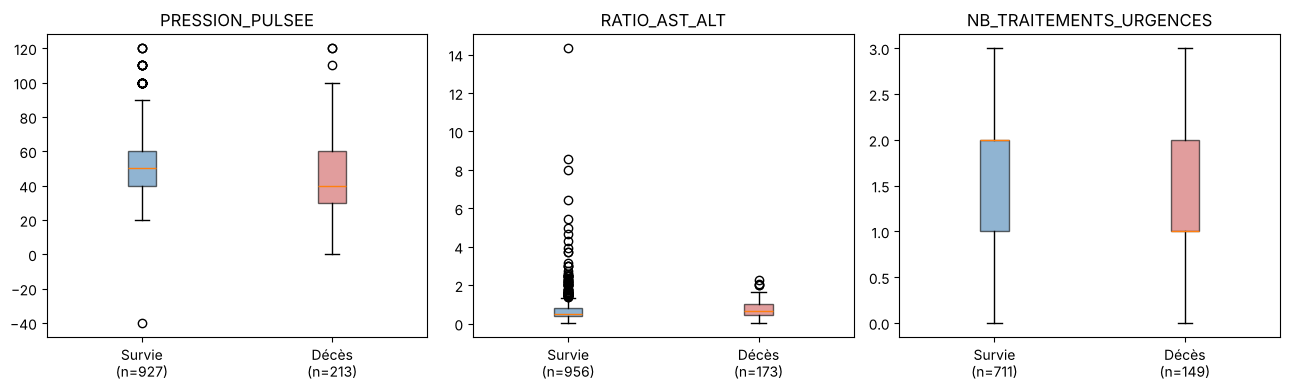

In [15]:
exploration_fe = X_j3_train[NOUVELLES_VARIABLES].copy()
exploration_fe["groupe"] = y_train.map({0: "Survie", 1: "Décès"})

lignes = []
for col in NOUVELLES_VARIABLES:
    surv = exploration_fe.loc[exploration_fe["groupe"] == "Survie", col].dropna()
    dec = exploration_fe.loc[exploration_fe["groupe"] == "Décès", col].dropna()
    _, p = mannwhitneyu(surv, dec)
    lignes.append({"variable": col, "médiane survie": surv.median(), "médiane décès": dec.median(),
                   "moyenne survie": surv.mean(), "moyenne décès": dec.mean(),
                   "n survie": len(surv), "n décès": len(dec), "p-value": p})
display(pd.DataFrame(lignes).set_index("variable").round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, NOUVELLES_VARIABLES):
    donnees = [exploration_fe.loc[exploration_fe["groupe"] == g, col].dropna() for g in ("Survie", "Décès")]
    bp = ax.boxplot(donnees, patch_artist=True)
    for patch, couleur in zip(bp["boxes"], ("steelblue", "indianred")):
        patch.set_facecolor(couleur); patch.set_alpha(0.6)
    ax.set_xticks([1, 2])
    ax.set_xticklabels([f"Survie\n(n={len(donnees[0])})", f"Décès\n(n={len(donnees[1])})"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Interprétation.** Les trois nouvelles variables diffèrent significativement entre survivants et décédés (p < 0,05), avec des effets d'intensité variable :
- **`PRESSION_PULSEE`** : médiane de 40 mmHg chez les décédés contre 50 mmHg chez les survivants (p < 0,001). L'hypothèse médicale est confirmée : une pression pulsée basse, signe d'un faible volume éjecté par le cœur, est associée au décès.
- **`RATIO_AST_ALT`** : rapport plus élevé chez les décédés (médiane 0,64 contre 0,50, p = 0,035), alors que l'ALAT et l'ASAT prises séparément n'étaient pas discriminantes (III.2). Le rapport des deux enzymes apporte une information que chacune n'apportait pas seule : c'est tout l'intérêt du feature engineering.
- **`NB_TRAITEMENTS_URGENCES`** : les patients décédés ont reçu un peu moins de traitements de l'équipe d'urgence (1,45 en moyenne contre 1,62, p = 0,038). L'effet est faible et difficile à interpréter (gravité, délai ou organisation de la prise en charge). La variable est manquante pour 37 % des patients, ceux pour qui les trois traitements de l'équipe d'urgence sont manquants.

L'utilité réelle de ces variables pour le modèle est mesurée par leur importance en IX.4.

## <a id="partie-V"></a>V - Preprocessing des données

### V.1 - Suppression des colonnes trop vides

**Objectif.** Retirer les variables qui contiennent trop de valeurs manquantes : les imputer reviendrait à inventer la majorité de leurs valeurs.

Ce traitement est appliqué séparément aux deux jeux de données (**ADM** et **J3**), chacun ayant sa propre liste de colonnes supprimées.

**Choix méthodologiques**

- **Seuil de 40 %** : valeur courante en pratique, qui représente un bon compromis entre conserver de l'information et éviter les colonnes trop pauvres. Ce seuil reste un paramètre ajustable (`SEUIL_NA`).
- **Absence de fuite de données (*data leakage*)** : les colonnes à supprimer sont déterminées à partir du jeu d'entraînement seul.
- **Cohérence des schémas** : une vérification (`assert`) contrôle que le jeu d'entraînement et le jeu de test ont exactement les mêmes colonnes, dans le même ordre, ce qui est nécessaire pour les étapes suivantes (imputation, standardisation, modélisation).

In [16]:
# --- Paramètres ---
SEUIL_NA = 0.4  # on supprime les colonnes avec plus de 40 % de valeurs manquantes
NA_DEGUISES = ["", "?", "unknown", "N/A"]   # par sécurité : ce CSV n'en contient pas (cases vides -> NaN)

def supprimer_colonnes_vides(X_train, X_test, seuil=SEUIL_NA, nom=""):
    """Détermine les colonnes trop vides sur X_train, puis les retire de X_train et X_test."""
    # Harmonisation des NA déguisés
    X_train = X_train.replace(NA_DEGUISES, np.nan)
    X_test = X_test.replace(NA_DEGUISES, np.nan)

    # Taux de NA calculé sur le TRAIN uniquement
    taux_na = X_train.isna().mean().sort_values(ascending=False)
    cols_a_supprimer = taux_na[taux_na > seuil].index.tolist()

    # Récapitulatif (colonnes au-dessus de 10 % de NA ; la liste complète est dans taux_na)
    print(f"===== {nom} =====")
    print("Taux de NA (train) des colonnes avec plus de 10 % de valeurs manquantes :")
    print((taux_na[taux_na > 0.10] * 100).round(2).to_string(), "\n")
    print(f"Colonnes supprimées ({len(cols_a_supprimer)}) : {cols_a_supprimer}")

    # Application identique au train et au test
    X_train_clean = X_train.drop(columns=cols_a_supprimer)
    X_test_clean = X_test.drop(columns=cols_a_supprimer, errors="ignore")

    print(f"Train : {X_train.shape} -> {X_train_clean.shape}")
    print(f"Test  : {X_test.shape} -> {X_test_clean.shape}\n")

    # Sécurité : mêmes colonnes, dans le même ordre
    assert list(X_train_clean.columns) == list(X_test_clean.columns), \
        f"{nom} : les colonnes de train et de test ne correspondent pas"

    return X_train_clean, X_test_clean, cols_a_supprimer


# --- Application aux deux jeux de données ---
X_adm_train_clean, X_adm_test_clean, cols_supp_adm = supprimer_colonnes_vides(
    X_adm_train, X_adm_test, nom="ADM"
)

X_j3_train_clean, X_j3_test_clean, cols_supp_j3 = supprimer_colonnes_vides(
    X_j3_train, X_j3_test, nom="J3"
)

===== ADM =====
Taux de NA (train) des colonnes avec plus de 10 % de valeurs manquantes :
KFK_BLOOD                  99.71
IBS_NASL                   95.29
S_AD_KBRIG                 63.46
D_AD_KBRIG                 63.46
NOT_NA_KB                  40.22
LID_KB                     39.63
NA_KB                      38.24
NB_TRAITEMENTS_URGENCES    36.76
NA_BLOOD                   22.87
GIPER_NA                   22.87
K_BLOOD                    22.65
GIPO_K                     22.50
RATIO_AST_ALT              16.99
AST_BLOOD                  16.91
ALT_BLOOD                  16.84
D_AD_ORIT                  16.18
S_AD_ORIT                  16.18
PRESSION_PULSEE            16.18
DLIT_AG                    14.34
ROE                        12.43 

Colonnes supprimées (5) : ['KFK_BLOOD', 'IBS_NASL', 'S_AD_KBRIG', 'D_AD_KBRIG', 'NOT_NA_KB']
Train : (1360, 97) -> (1360, 92)
Test  : (340, 97) -> (340, 92)

===== J3 =====
Taux de NA (train) des colonnes avec plus de 10 % de valeurs manquantes :
K

**Interprétation.** Les deux scénarios perdent les mêmes 5 colonnes : `KFK_BLOOD` (99,7 % de valeurs manquantes), `IBS_NASL` (95,3 %), `S_AD_KBRIG` et `D_AD_KBRIG` (63,5 %) et `NOT_NA_KB` (40,2 %). Il reste 92 variables pour l'admission et 109 pour le jour 3. Deux remarques :
- `NOT_NA_KB` est supprimée de justesse alors que `LID_KB` (39,6 %) et `NA_KB` (38,2 %) sont conservées, avec les mêmes patients manquants : c'est l'effet de seuil d'une règle fixe. Son information est en partie conservée dans `NB_TRAITEMENTS_URGENCES`, calculée avant la suppression.
- La pression mesurée par l'équipe d'urgence (`S_AD_KBRIG`) était discriminante (III.2), mais elle est en grande partie remplacée par la pression en soins intensifs, connue pour 84 % des patients.

### V.2 - Imputation des valeurs manquantes

Cette étape remplace les valeurs manquantes de chaque colonne par une valeur qui introduit le moins de biais possible. Elle permet d'utiliser le jeu de données avec des modèles qui ne supportent pas les valeurs manquantes (SVM, régression logistique, ACP, k-means). Elle n'est pas indispensable pour XGBoost, qui sait gérer les valeurs manquantes nativement ; nous l'utilisons quand même pour tous les modèles afin de les comparer sur les mêmes données.
- On utilise la **médiane** pour les variables continues (moins sensible aux valeurs extrêmes que la moyenne).
- On utilise le **mode** (valeur la plus fréquente) pour les variables binaires et ordinales, pour que la valeur imputée reste une modalité possible.

Les médianes et les modes sont calculés sur le **train** uniquement.

In [17]:
def imputer_mediane_mode(X_train, X_test, resume, nom=""):
    """Médiane pour les variables continues, mode pour les binaires et ordinales.
    L'imputeur est ajusté sur le train uniquement, puis appliqué au train et au test."""
    # On ne garde que les colonnes encore présentes après l'étape V.1
    cols_cont = [c for c in X_train.columns if resume.loc[c, "type"] == "continue"]
    cols_mode = [c for c in X_train.columns if resume.loc[c, "type"] in ("binaire", "ordinale")]

    imputeur = ColumnTransformer(
        transformers=[
            ("mediane", SimpleImputer(strategy="median"), cols_cont),
            ("mode", SimpleImputer(strategy="most_frequent"), cols_mode),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

    X_train_imp = imputeur.fit_transform(X_train)   # fit sur le train uniquement
    X_test_imp = imputeur.transform(X_test)         # simple application au test

    # Retour à l'ordre d'origine des colonnes
    X_train_imp = X_train_imp[X_train.columns]
    X_test_imp = X_test_imp[X_train.columns]

    print(f"===== {nom} =====")
    print(f"Continues (médiane) : {len(cols_cont)} | Binaires/ordinales (mode) : {len(cols_mode)}")
    print(f"NA restants - train : {X_train_imp.isna().sum().sum()} | test : {X_test_imp.isna().sum().sum()}\n")

    return X_train_imp, X_test_imp, imputeur


# --- Application aux deux jeux de données (après la suppression des colonnes vides) ---
X_adm_train_imp, X_adm_test_imp, imp_adm = imputer_mediane_mode(
    X_adm_train_clean, X_adm_test_clean, resume_all, nom="ADM"
)
X_j3_train_imp, X_j3_test_imp, imp_j3 = imputer_mediane_mode(
    X_j3_train_clean, X_j3_test_clean, resume_all, nom="J3"
)

# Les nouvelles variables de la partie IV sont bien présentes dans les données imputées
assert all(v in X_adm_train_imp.columns and v in X_j3_train_imp.columns for v in NOUVELLES_VARIABLES)

===== ADM =====
Continues (médiane) : 11 | Binaires/ordinales (mode) : 81
NA restants - train : 0 | test : 0

===== J3 =====
Continues (médiane) : 11 | Binaires/ordinales (mode) : 98
NA restants - train : 0 | test : 0



### V.3 - Standardisation des colonnes continues

**Objectif.** Mettre les variables continues à la même échelle (moyenne 0, écart-type 1). Sans cela, les variables aux grandes valeurs dominent les modèles sensibles à l'échelle (régression logistique, SVM, KNN, réseaux de neurones), et la régularisation (L1/L2, Elastic Net) pénalise les coefficients de façon inégale.

**Méthode**

- Utilisation de `StandardScaler` sur les variables de type **continue** uniquement (repérées grâce au tableau des types).
- Les variables **binaires** et **ordinales** restent inchangées, car les standardiser ferait perdre leur interprétation.
- Le scaler est **ajusté sur le jeu d'entraînement uniquement**, puis appliqué au jeu de test, afin d'éviter toute fuite de données.
- Traitement appliqué séparément aux jeux **ADM** et **J3**.

**Vérification.** Sur le train, les variables continues ont une moyenne proche de 0 et un écart-type de 1. Sur le test, les valeurs sont proches mais pas exactes, ce qui est normal.

**Quels modèles utilisent quelles données ?** XGBoost, à base d'arbres, n'est pas sensible à l'échelle : il utilise les données imputées (`_imp`). Le SVM et la régression logistique utilisent les données standardisées (`_sc`).

In [18]:
def standardiser_continues(X_train, X_test, resume, nom=""):
    """Standardise uniquement les variables continues (moyenne 0, écart-type 1).
    Le scaler est ajusté sur le train uniquement, puis appliqué au test."""
    cols_cont = [c for c in X_train.columns if resume.loc[c, "type"] == "continue"]

    scaler = ColumnTransformer(
        transformers=[("scale", StandardScaler(), cols_cont)],
        remainder="passthrough",              # binaires et ordinales inchangées
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

    X_train_sc = scaler.fit_transform(X_train)   # fit sur le train uniquement
    X_test_sc = scaler.transform(X_test)

    # Retour à l'ordre d'origine des colonnes
    X_train_sc = X_train_sc[X_train.columns]
    X_test_sc = X_test_sc[X_train.columns]

    print(f"===== {nom} =====")
    print(f"Variables standardisées ({len(cols_cont)}) : {cols_cont}")
    max_mean = round(X_train_sc[cols_cont].mean().abs().max(), 6)
    unique_std = X_train_sc[cols_cont].std(ddof=0).round(6).unique()[:3]
    print("Train - moyenne ~0 :", max_mean,
          "| écart-type ~1 :", unique_std, "\n")

    return X_train_sc, X_test_sc, scaler


X_adm_train_sc, X_adm_test_sc, scaler_adm = standardiser_continues(
    X_adm_train_imp, X_adm_test_imp, resume_all, nom="ADM"
)
X_j3_train_sc, X_j3_test_sc, scaler_j3 = standardiser_continues(
    X_j3_train_imp, X_j3_test_imp, resume_all, nom="J3"
)

===== ADM =====
Variables standardisées (11) : ['AGE', 'S_AD_ORIT', 'D_AD_ORIT', 'K_BLOOD', 'NA_BLOOD', 'ALT_BLOOD', 'AST_BLOOD', 'L_BLOOD', 'ROE', 'PRESSION_PULSEE', 'RATIO_AST_ALT']
Train - moyenne ~0 : 0.0 | écart-type ~1 : [1.] 

===== J3 =====
Variables standardisées (11) : ['AGE', 'S_AD_ORIT', 'D_AD_ORIT', 'K_BLOOD', 'NA_BLOOD', 'ALT_BLOOD', 'AST_BLOOD', 'L_BLOOD', 'ROE', 'PRESSION_PULSEE', 'RATIO_AST_ALT']
Train - moyenne ~0 : 0.0 | écart-type ~1 : [1.] 



### V.4 - Déséquilibre des classes

Les décès ne représentent que 16 % des patients. Un modèle entraîné sans correction minimise son erreur globale en prédisant presque toujours « survie » (hypothèse H3). Deux familles de solutions existent :
- **ré-échantillonner** les données (sous-échantillonner les survivants, ou créer des décès synthétiques avec SMOTE) ;
- **pondérer les erreurs** : une erreur sur un décès coûte plus cher qu'une erreur sur un survivant.

Nous choisissons la **pondération**, qui ne modifie pas les données et ne crée pas de patients artificiels. Les poids `balanced` sont inversement proportionnels à la fréquence de chaque classe (calculés sur le train) :
- pour le SVM et la régression logistique : `class_weight="balanced"` ;
- pour XGBoost : `scale_pos_weight` = nombre de survivants / nombre de décès, ce qui donne exactement le même rapport entre les deux poids.

In [19]:
def poids_de_classes(y_train, nom=""):
    """Affiche la répartition des classes et les poids 'balanced' calculés sur le train."""
    classes = np.unique(y_train)
    poids = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)

    resume = pd.DataFrame({
        "effectif": pd.Series(y_train).value_counts().sort_index(),
        "proportion (%)": (pd.Series(y_train).value_counts(normalize=True).sort_index() * 100).round(2),
        "poids balanced": poids.round(3),
    })
    print(f"===== {nom} =====")
    print(resume, "\n")
    return dict(zip(classes, poids))

# La cible et les patients du train sont les mêmes pour les scénarios ADM et J3
poids_adm = poids_de_classes(y_train, nom="Train (identique pour ADM et J3)")
print(f"Rapport des poids décès / survie : {poids_adm[1] / poids_adm[0]:.2f} "
      "(= scale_pos_weight utilisé par XGBoost)")

===== Train (identique pour ADM et J3) =====
       effectif  proportion (%)  poids balanced
deces                                          
0          1143           84.04           0.595
1           217           15.96           3.134 

Rapport des poids décès / survie : 5.27 (= scale_pos_weight utilisé par XGBoost)


## <a id="partie-VI"></a>VI - Exploration non supervisée : ACP et clustering

Avant d'entraîner des modèles supervisés, on regarde la structure des données **sans utiliser la cible** : c'est de l'**apprentissage non supervisé**. C'est aussi l'approche de l'article de référence, qui projette les patients sur leurs 12 premières composantes principales avant de construire un arbre principal élastique (une généralisation non linéaire de l'ACP).

Deux questions :
1. **ACP (PCA)** : les 109 variables contiennent-elles beaucoup d'information redondante ? Les décès se distinguent-ils déjà sur les principaux axes de variation ?
2. **Clustering (k-means)** : existe-t-il des groupes naturels de patients, et ces groupes ont-ils des taux de décès différents ?

On travaille sur le **train** du scénario Jour 3, après imputation (l'ACP et le k-means n'acceptent pas les valeurs manquantes).

### VI.1 - Analyse en composantes principales (ACP)

L'ACP construit de nouveaux axes (les composantes principales), combinaisons linéaires des variables d'origine, qui résument le maximum de variance avec le minimum d'axes. Elle est sensible à l'échelle : on standardise ici **toutes** les colonnes (y compris binaires et ordinales), sinon une ordinale comme `TIME_B_S` (de 1 à 9) écraserait les variables binaires (0 ou 1). Cette standardisation sert uniquement à l'ACP et au k-means.

Nombre de variables : 109
Variance expliquée : PC1 3.5% | PC2 3.3% | PC1 + PC2 6.8%
Composantes nécessaires pour 50% de la variance : 31
Composantes nécessaires pour 80% de la variance : 63
Composantes nécessaires pour 90% de la variance : 79
AUC de PC1 pour séparer décès et survivants : 0.803
AUC de PC2 pour séparer décès et survivants : 0.585


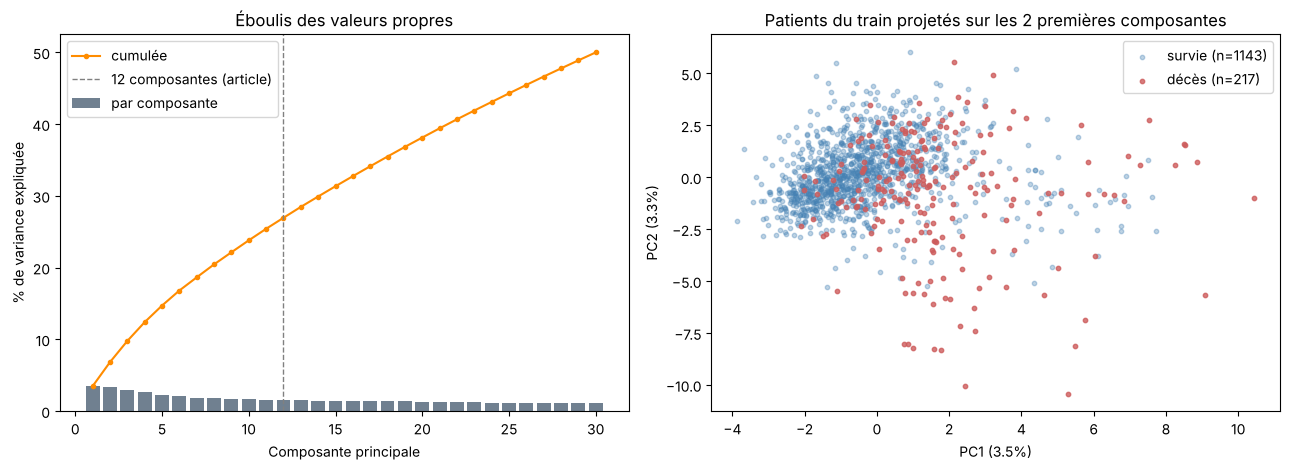


PC1 : variables les plus contributives (coefficient)
ritm_ecg_p_02    0.31
MP_TP_POST       0.31
ritm_ecg_p_01   -0.26
FK_STENOK        0.24
nr_04            0.23
n_r_ecg_p_06     0.22
n_r_ecg_p_05     0.22
AGE              0.22

PC2 : variables les plus contributives (coefficient)
S_AD_ORIT          0.44
D_AD_ORIT          0.39
PRESSION_PULSEE    0.36
K_SH_POST         -0.26
DLIT_AG            0.25
GB                 0.24
SEX               -0.14
ANT_CA_S_n         0.13


In [20]:
# Standardisation de toutes les colonnes (ajustée sur le train) : uniquement pour l'ACP et le k-means
scaler_pca = StandardScaler()
Z_train = scaler_pca.fit_transform(X_j3_train_imp)

pca = PCA(random_state=SEED)
Z_pca = pca.fit_transform(Z_train)
var_exp = pca.explained_variance_ratio_
var_cum = np.cumsum(var_exp)

print(f"Nombre de variables : {Z_train.shape[1]}")
print(f"Variance expliquée : PC1 {var_exp[0]:.1%} | PC2 {var_exp[1]:.1%} | PC1 + PC2 {var_cum[1]:.1%}")
for part in (0.5, 0.8, 0.9):
    print(f"Composantes nécessaires pour {part:.0%} de la variance : {np.searchsorted(var_cum, part) + 1}")

# Les décès se distinguent-ils sur les deux premiers axes ? (AUC de la composante prise comme score)
for i in range(2):
    auc_pc = roc_auc_score(y_train, Z_pca[:, i])
    print(f"AUC de PC{i + 1} pour séparer décès et survivants : {max(auc_pc, 1 - auc_pc):.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# Éboulis des valeurs propres (30 premières composantes)
k_aff = 30
ax1.bar(range(1, k_aff + 1), var_exp[:k_aff] * 100, color="slategray", label="par composante")
ax1.plot(range(1, k_aff + 1), var_cum[:k_aff] * 100, "o-", ms=3, color="darkorange", label="cumulée")
ax1.axvline(12, color="gray", linestyle="--", lw=1, label="12 composantes (article)")
ax1.set_xlabel("Composante principale"); ax1.set_ylabel("% de variance expliquée")
ax1.set_title("Éboulis des valeurs propres"); ax1.legend()

# Projection des patients du train sur PC1 / PC2, colorés par l'issue (la cible ne sert qu'à colorer)
for g, couleur, alpha in [(0, "steelblue", 0.35), (1, "indianred", 0.8)]:
    m = y_train.values == g
    ax2.scatter(Z_pca[m, 0], Z_pca[m, 1], s=10, alpha=alpha, color=couleur, label=f"{LABELS[g]} (n={m.sum()})")
ax2.set_xlabel(f"PC1 ({var_exp[0]:.1%})"); ax2.set_ylabel(f"PC2 ({var_exp[1]:.1%})")
ax2.set_title("Patients du train projetés sur les 2 premières composantes"); ax2.legend()
plt.tight_layout()
plt.show()

# Variables qui contribuent le plus aux deux premières composantes
charges = pd.DataFrame(pca.components_[:2].T, index=X_j3_train_imp.columns, columns=["PC1", "PC2"])
for pc in ["PC1", "PC2"]:
    top_pc = charges[pc].abs().sort_values(ascending=False).head(8).index
    print(f"\n{pc} : variables les plus contributives (coefficient)")
    print(charges.loc[top_pc, pc].round(2).to_string())

**Interprétation.** 

- **Peu de redondance globale.** Les deux premières composantes n'expliquent que 6,8 % de la variance, et il faut 31 composantes pour en expliquer la moitié, 63 pour 80 %. L'éboulis ne présente pas de coude net. Les variables cliniques, surtout binaires, apportent chacune une information en partie indépendante : une réduction de dimension forte ferait perdre beaucoup d'information. Les 12 composantes retenues par l'article ne conservent ici que 26,9 % de la variance. L'article travaille dans un espace différent (variables ordinales recodées de façon optimale), où les deux premières composantes expliquent 25,9 % de la variance.
- **Un axe de gravité trouvé sans la cible.** La première composante est portée par la fibrillation auriculaire (`ritm_ecg_p_02`, `MP_TP_POST`, `n_r_ecg_p_05`, `n_r_ecg_p_06`, antécédent `nr_04`), l'absence de rythme sinusal normal (`ritm_ecg_p_01`, coefficient négatif), la classe d'angine (`FK_STENOK`) et l'âge. Sur le nuage de points, les décès sont nettement décalés vers les valeurs élevées de PC1 : prise comme score, PC1 sépare décès et survivants avec une AUC de 0,80, alors que l'ACP n'a jamais vu la cible. La deuxième composante résume la pression artérielle (`S_AD_ORIT`, `D_AD_ORIT`, `PRESSION_PULSEE`, avec le choc cardiogénique `K_SH_POST` en sens opposé) : les décès sont aussi plus fréquents vers les valeurs basses de PC2 (pressions basses).
- **Limite.** Malgré ce décalage, les deux nuages se recouvrent largement : deux axes linéaires ne suffisent pas à isoler les décès, d'où l'intérêt des modèles supervisés.

### VI.2 - Clustering des patients (k-means)

Le **k-means** regroupe les patients en *k* groupes (*clusters*) de façon à ce que les patients d'un même groupe soient proches les uns des autres. On l'applique dans l'espace des **12 premières composantes principales** (comme dans l'article), ce qui élimine une partie du bruit des 109 variables.

Le nombre de groupes *k* est un **hyperparamètre** : on le choisit avec deux critères calculés pour *k* de 2 à 8 :
- l'**inertie** (somme des distances au centre du groupe) : elle diminue toujours quand *k* augmente, on cherche un « coude » ;
- le **score de silhouette** (entre −1 et 1) : il mesure si chaque patient est plus proche de son groupe que du groupe voisin ; on retient le *k* qui le maximise.

Variance conservée par les 12 premières composantes : 26.9%


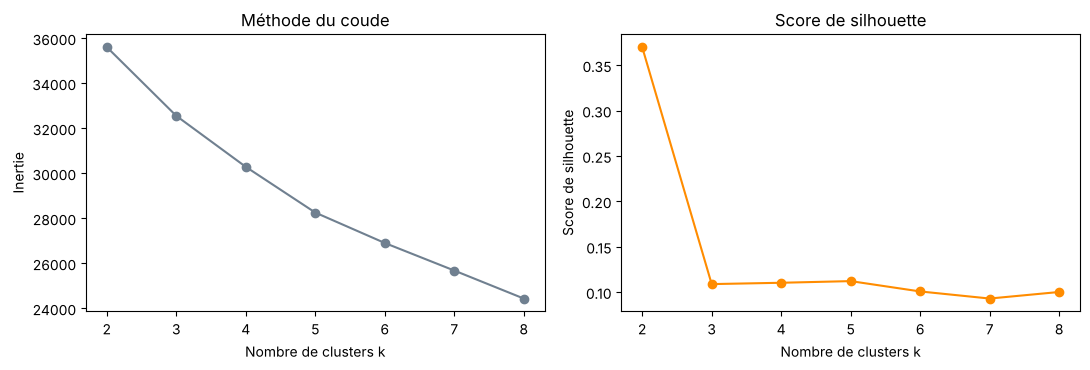

k retenu (meilleure silhouette) : 2 (silhouette = 0.370)


,patients,% décès
cluster,,
0,1280,14.8
1,80,35.0


Taux de décès global du train : 16.0%

Cluster 0 : variables les plus caractéristiques (écart à la moyenne, en écarts-types)
ritm_ecg_p_02   -0.23
MP_TP_POST      -0.22
n_r_ecg_p_05    -0.17
n_r_ecg_p_06    -0.13
nr_04           -0.12
ritm_ecg_p_01    0.09

Cluster 1 : variables les plus caractéristiques (écart à la moyenne, en écarts-types)
ritm_ecg_p_02    3.73
MP_TP_POST       3.53
n_r_ecg_p_05     2.73
n_r_ecg_p_06     2.05
nr_04            1.95
ritm_ecg_p_01   -1.45


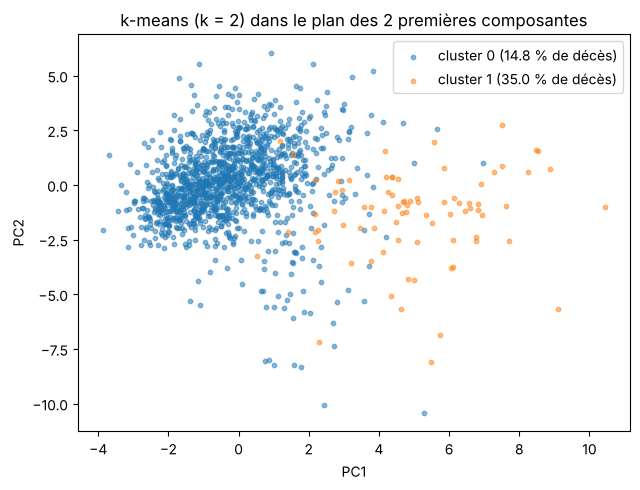

In [21]:
N_COMPOSANTES = 12                 # nombre de composantes retenu par les auteurs de l'article
Z_red = Z_pca[:, :N_COMPOSANTES]
print(f"Variance conservée par les {N_COMPOSANTES} premières composantes : {var_cum[N_COMPOSANTES - 1]:.1%}")

ks = list(range(2, 9))
inerties, silhouettes = [], []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z_red)
    inerties.append(km_k.inertia_)
    silhouettes.append(silhouette_score(Z_red, km_k.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(ks, inerties, "o-", color="slategray")
ax1.set_xlabel("Nombre de clusters k"); ax1.set_ylabel("Inertie"); ax1.set_title("Méthode du coude")
ax2.plot(ks, silhouettes, "o-", color="darkorange")
ax2.set_xlabel("Nombre de clusters k"); ax2.set_ylabel("Score de silhouette"); ax2.set_title("Score de silhouette")
plt.tight_layout()
plt.show()

K_RETENU = ks[int(np.argmax(silhouettes))]
print(f"k retenu (meilleure silhouette) : {K_RETENU} (silhouette = {max(silhouettes):.3f})")

# Clustering final et taux de décès par cluster (la cible n'a pas servi à former les groupes)
km = KMeans(n_clusters=K_RETENU, n_init=10, random_state=SEED).fit(Z_red)
clusters = pd.Series(km.labels_, index=X_j3_train_imp.index, name="cluster")

profil = pd.DataFrame({
    "patients": clusters.value_counts().sort_index(),
    "% décès": (y_train.groupby(clusters).mean() * 100).round(1),
})
display(profil)
print(f"Taux de décès global du train : {y_train.mean():.1%}")

# Description automatique : variables dont la moyenne (standardisée) s'écarte le plus de la moyenne générale
Z_df = pd.DataFrame(Z_train, index=X_j3_train_imp.index, columns=X_j3_train_imp.columns)
for c in range(K_RETENU):
    ecarts = Z_df[clusters == c].mean().sort_values(key=abs, ascending=False).head(6)
    print(f"\nCluster {c} : variables les plus caractéristiques (écart à la moyenne, en écarts-types)")
    print(ecarts.round(2).to_string())

# Visualisation des clusters dans le plan PC1 / PC2
plt.figure(figsize=(6.5, 5))
for c in range(K_RETENU):
    m = clusters.values == c
    plt.scatter(Z_pca[m, 0], Z_pca[m, 1], s=10, alpha=0.5,
                label=f"cluster {c} ({profil.loc[c, '% décès']} % de décès)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"k-means (k = {K_RETENU}) dans le plan des 2 premières composantes")
plt.legend()
plt.tight_layout()
plt.show()

**Interprétation.** 

- **Choix de k.** Le score de silhouette est maximal pour k = 2 (0,37) ; l'inertie décroît régulièrement, sans coude marqué, ce qui confirme que les patients ne forment pas de groupes très séparés.
- **Un petit groupe à haut risque.** Le k-means isole un cluster de 80 patients (6 % du train) caractérisé par la **fibrillation auriculaire** : rythme en fibrillation à l'ECG d'admission (`ritm_ecg_p_02`, +3,7 écarts-types par rapport à la moyenne), accès de fibrillation à l'arrivée en soins intensifs (`MP_TP_POST`), fibrillation paroxystique ou persistante à l'ECG et dans les antécédents, absence de rythme sinusal. Ce groupe a un taux de décès de **35 %**, plus du double de celui des autres patients (14,8 %), alors que la cible n'a pas servi à le former.
- **Lien avec le cas d'usage et l'article.** Dans l'article, les troubles du rythme auriculaire structurent aussi l'une des branches de l'arbre principal (le long de laquelle les accès de fibrillation auriculaire augmentent, avec un pronostic jugé plutôt favorable). La fibrillation auriculaire est donc un axe majeur de la structure des données, mais son lien avec le décès dépend du contexte : ici, une fibrillation déjà présente à l'admission.
- **Limite et perspective.** Le clustering ne remplace pas un modèle supervisé : le grand cluster contient encore environ 87 % des décès. L'appartenance au cluster pourrait être ajoutée comme variable (feature engineering non supervisé), ou remplacée par la méthode de l'article (arbre principal élastique), mieux adaptée à des trajectoires continues qu'à des groupes séparés.

## <a id="partie-VII"></a>VII - Apprentissage et réglage des hyperparamètres (scénario Admission)

### VII.1 - Démarche : validation croisée, surapprentissage et hyperparamètres

Un modèle doit être bon sur des patients **qu'il n'a jamais vus**. S'il apprend « par cœur » les particularités du train (bruit, cas isolés), il est excellent sur le train mais mauvais sur de nouveaux patients : c'est le **surapprentissage** (*overfitting*). À l'inverse, un modèle trop simple rate les vraies tendances : c'est le sous-apprentissage.

Les **hyperparamètres** (profondeur des arbres, nombre d'arbres, pénalité `C` du SVM…) ne sont pas appris par le modèle : c'est nous qui les fixons, et ils règlent ce compromis. Pour les choisir sans toucher au jeu de test, on utilise la **validation croisée** sur le train :
- le train est découpé en 5 plis (`cv`, stratifié : chaque pli garde environ 16 % de décès) ;
- chaque pli sert à tour de rôle de validation pendant que le modèle s'entraîne sur les 4 autres ;
- le score retenu est la moyenne des 5 scores de validation.

La méthode de recherche choisie pour trouver la meilleure combinaison d'hyperparamètres est la **recherche aléatoire** (*Random Search*) : elle teste un nombre fixé de combinaisons tirées au hasard, ce qui est un bon compromis entre performance et temps de calcul (une recherche exhaustive testerait ici 1 296 combinaisons pour XGBoost).

Les modèles retenus sont **XGBoost** (gradient boosting d'arbres de décision) et un **SVM** (classifieur à vaste marge), comparés à deux modèles de référence (voir le tableau du 0.7). Le score optimisé est le **F1-score** de la classe « décès » ; le **recall** est ensuite fixé à 80 % grâce au choix du seuil de décision (partie VIII).

### VII.2 - XGBoost avec réglages par défaut

Avant de régler les hyperparamètres, on mesure les performances d'un XGBoost **non réglé**. Ce score sert de référence : le réglage n'est utile que s'il fait mieux.

Ce que fait la cellule :

1. **Validation croisée** : on utilise le découpage `cv` défini au début du notebook (5 plis stratifiés, `shuffle=True` pour mélanger les patients avant le découpage, `random_state=SEED` pour rendre le résultat reproductible).

2. **Modèle de base** : un `XGBClassifier` avec ses réglages par défaut, sauf deux paramètres :
   - `scale_pos_weight=ratio_classes` donne aux décès un poids environ 5,3 fois plus fort pendant l'apprentissage. Sans lui, le modèle serait tenté de prédire presque toujours « survie » ;
   - `eval_metric="logloss"` fixe la mesure d'erreur interne utilisée par XGBoost pendant l'entraînement. Elle n'influence pas le score affiché ci-dessous.

3. **Score** : `cross_val_score` entraîne le modèle 5 fois et renvoie un **F1-score** par pli. Le F1 de la classe « décès » est la moyenne harmonique entre la précision (parmi les patients annoncés à risque, combien sont vraiment décédés) et le recall (parmi les décès réels, combien sont détectés). Il est bas si l'un des deux est faible, ce qui le rend adapté à une classe rare.

In [22]:
# Ratio pour le déséquilibre de classes, calculé sur le train (1143 survies / 217 décès ≈ 5.3)
ratio_classes = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {ratio_classes:.2f}")

# Modèle de base
xgb_base = XGBClassifier(
    scale_pos_weight=ratio_classes,  # compense le déséquilibre
    eval_metric="logloss",
    random_state=SEED
)

# Évaluation en validation croisée sur le train (cv défini en I.1)
scores_f1 = cross_val_score(xgb_base, X_adm_train_imp, y_train, cv=cv, scoring="f1")

print(f"F1-scores (5 plis) : {scores_f1.round(3)}")
print(f"F1-score moyen : {scores_f1.mean():.3f} (± {scores_f1.std():.3f})")

scale_pos_weight = 5.27
F1-scores (5 plis) : [0.568 0.528 0.649 0.585 0.532]
F1-score moyen : 0.572 (± 0.044)


**Lecture du résultat.** Le F1-score moyen de XGBoost par défaut est de 0,572, avec un écart-type de 0,044 entre les plis (de 0,53 à 0,65). Cette variabilité est attendue avec seulement 217 décès dans le train (environ 43 par pli de validation) : le score dépend du pli choisi. Cette moyenne est le score à battre lors du réglage des hyperparamètres (VII.4).

### VII.3 - Modèles de référence et effet de la pondération des classes (H3)

Pour savoir si nos modèles apportent vraiment quelque chose, on les compare, toujours en validation croisée sur le train, à :
- un **`DummyClassifier`** qui prédit « décès » au hasard, avec la fréquence observée (16 %) : c'est le niveau d'un modèle qui n'apprend rien ;
- une **régression logistique** pondérée (`class_weight="balanced"`), sur les données standardisées : c'est le modèle linéaire classique des scores de risque cliniques.

On compare aussi XGBoost **avec et sans** `scale_pos_weight`, pour tester l'hypothèse **H3** (faut-il corriger le déséquilibre des classes ?). `cross_validate` permet de calculer plusieurs métriques à la fois ; les métriques dépendant d'un seuil sont calculées au seuil par défaut (0,5).

,recall,precision,f1,roc_auc
modèle,,,,
Dummy (hasard stratifié),0.152,0.143,0.148,0.490
Régression logistique (balanced),0.733,0.442,0.550,0.857
XGBoost sans pondération,0.452,0.661,0.536,0.863
XGBoost avec scale_pos_weight,0.525,0.636,0.572,0.872


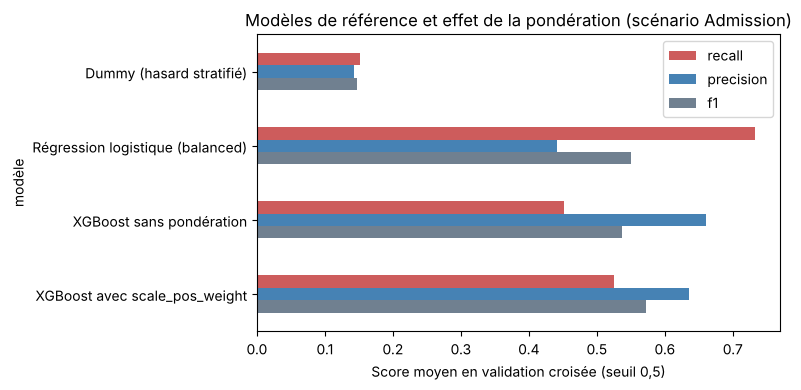

In [23]:
METRIQUES_CV = {"recall": "recall", "precision": "precision", "f1": "f1", "roc_auc": "roc_auc"}

modeles_reference = {
    "Dummy (hasard stratifié)":             (DummyClassifier(strategy="stratified", random_state=SEED), X_adm_train_imp),
    "Régression logistique (balanced)":     (LogisticRegression(class_weight="balanced", max_iter=5000), X_adm_train_sc),
    "XGBoost sans pondération":             (XGBClassifier(eval_metric="logloss", random_state=SEED), X_adm_train_imp),
    "XGBoost avec scale_pos_weight":        (xgb_base, X_adm_train_imp),
}

lignes = []
for nom, (modele, X_cv) in modeles_reference.items():
    res = cross_validate(modele, X_cv, y_train, cv=cv, scoring=METRIQUES_CV)
    lignes.append({"modèle": nom, **{m: res[f"test_{m}"].mean() for m in METRIQUES_CV}})

tableau_reference = pd.DataFrame(lignes).set_index("modèle")
display(tableau_reference.round(3))

tableau_reference[["recall", "precision", "f1"]].plot(kind="barh", figsize=(8, 4),
                                                       color=["indianred", "steelblue", "slategray"])
plt.xlabel("Score moyen en validation croisée (seuil 0,5)")
plt.title("Modèles de référence et effet de la pondération (scénario Admission)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Interprétation.** 

- **Tous les modèles battent nettement le hasard** : le `DummyClassifier` obtient un F1 de 0,15 et une AUC de 0,49, alors que les trois autres modèles atteignent une AUC de 0,86 à 0,87. Les variables d'admission contiennent donc une vraie information sur le risque de décès (H1).
- **La régression logistique est une référence solide** : AUC de 0,857, à peine inférieure à celle de XGBoost (0,872). Avec `class_weight="balanced"`, elle a même le meilleur recall au seuil 0,5 (73 %), au prix d'une précision plus faible (44 %). L'apport de XGBoost par rapport à un modèle linéaire existe mais reste modeste.
- **Effet de la pondération (H3).** Sans pondération, XGBoost ne détecte que 45 % des décès au seuil 0,5 ; avec `scale_pos_weight`, il en détecte 52 % et son F1 passe de 0,536 à 0,572. En revanche, l'AUC change peu (0,863 contre 0,872) : la pondération ne rend pas le modèle beaucoup plus capable de **classer** les patients, elle **décale** surtout ses probabilités vers la classe « décès ». H3 est donc confirmée au seuil par défaut : sans correction, le modèle rate la majorité des décès. L'abaissement du seuil (partie VIII) joue un rôle complémentaire : pondération et choix du seuil sont deux façons de traiter le déséquilibre.

### VII.4 - Réglage des hyperparamètres de XGBoost (Random Search)

XGBoost par défaut n'est pas forcément le meilleur réglage pour nos données. On cherche donc la combinaison d'**hyperparamètres** qui donne le meilleur F1-score en validation croisée sur le train.

**Espace de recherche.** `param_grid` liste, pour six hyperparamètres, les valeurs à essayer :

| Hyperparamètre | Valeurs testées | Rôle |
|---|---|---|
| `n_estimators` | 100, 200, 300 | nombre d'arbres construits |
| `max_depth` | 3, 4, 6, 8 | profondeur maximale de chaque arbre |
| `learning_rate` | 0,01 ; 0,05 ; 0,1 ; 0,2 | poids de chaque nouvel arbre (pas d'apprentissage) |
| `subsample` | 0,7 ; 0,8 ; 1,0 | part des patients utilisée par chaque arbre |
| `colsample_bytree` | 0,6 ; 0,8 ; 1,0 | part des variables utilisée par chaque arbre |
| `min_child_weight` | 1, 3, 5 | poids minimal exigé dans une feuille |

L'espace contient 3 × 4 × 4 × 3 × 3 × 3 = 1 296 combinaisons ; la recherche aléatoire en teste 20. On demande aussi les scores sur les plis d'entraînement (`return_train_score=True`) : un écart important entre le score d'entraînement et le score de validation est le signe d'un **surapprentissage**.

**Lecture du résultat.** On compare le meilleur F1 obtenu au F1 de XGBoost par défaut (VII.2). Un gain important montre que le réglage compte ; un gain faible signifie que le modèle est peu sensible à ces hyperparamètres, et que la difficulté vient plutôt des données (peu de décès, nombreuses valeurs manquantes).

In [24]:
# Grille d'hyperparamètres à explorer
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5]
}

search_adm = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=20,               # nombre de combinaisons testées
    cv=cv,                   # StratifiedKFold
    scoring="f1",            # optimisation ciblée sur le F1-score
    return_train_score=True, # pour mesurer l'écart train / validation (surapprentissage)
    random_state=SEED,
    n_jobs=-1
)

search_adm.fit(X_adm_train_imp, y_train)

print(f"Meilleur F1-score en CV : {search_adm.best_score_:.3f} (XGBoost par défaut : {scores_f1.mean():.3f})")
print("Meilleurs hyperparamètres :", search_adm.best_params_)
f1_train_best = search_adm.cv_results_["mean_train_score"][search_adm.best_index_]
print(f"F1 du meilleur modèle sur les plis d'entraînement : {f1_train_best:.3f} "
      f"-> écart train / validation : {f1_train_best - search_adm.best_score_:.3f}")

# Les 5 meilleures combinaisons testées
resultats_adm = pd.DataFrame(search_adm.cv_results_)
colonnes_res = ["param_" + p for p in param_grid] + ["mean_train_score", "mean_test_score", "std_test_score"]
display(resultats_adm.sort_values("rank_test_score")[colonnes_res].head(5).round(3))

Meilleur F1-score en CV : 0.575 (XGBoost par défaut : 0.572)
Meilleurs hyperparamètres : {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.01, 'colsample_bytree': 0.6}
F1 du meilleur modèle sur les plis d'entraînement : 0.855 -> écart train / validation : 0.280


,param_n_estimators,param_max_depth,param_learning_rate,param_subsample,param_colsample_bytree,param_min_child_weight,mean_train_score,mean_test_score,std_test_score
9,200,6,0.01,0.8,0.6,5,0.855,0.575,0.044
11,300,4,0.10,0.7,1.0,5,0.995,0.572,0.027
17,100,8,0.10,1.0,0.8,1,1.000,0.568,0.055
12,200,6,0.10,0.8,0.8,5,0.999,0.567,0.047
0,200,6,0.05,0.8,0.8,1,1.000,0.565,0.043


**Interprétation.** 

- **Gain faible.** Le meilleur F1 en validation croisée (0,575) dépasse à peine celui de XGBoost par défaut (0,572), et les 5 meilleures combinaisons sont très proches (0,565 à 0,575), avec des écarts-types de 0,03 à 0,05 entre plis. Le réglage compte donc peu ici : la difficulté vient des données (peu de décès, information répartie sur de nombreuses variables), pas des hyperparamètres. Avec seulement 20 combinaisons tirées au hasard, la combinaison retenue dépend aussi en partie du hasard du tirage.
- **Surapprentissage visible.** Les combinaisons avec un pas d'apprentissage de 0,05 ou 0,1 atteignent un F1 de 0,995 à 1,000 sur les plis d'entraînement : elles apprennent le train **par cœur**, sans être meilleures en validation. La combinaison retenue (`learning_rate=0.01`, 200 arbres de profondeur 6, `min_child_weight=5`, `subsample=0.8`, `colsample_bytree=0.6`) est la plus régularisée : son F1 d'entraînement est de 0,855, mais l'écart avec la validation (0,28) reste important.

### VII.5 - Discussion des hyperparamètres et courbes de validation

**Hyperparamètres importants de XGBoost et leur effet sur le surapprentissage**

| Hyperparamètre | Effet quand on l'augmente | Risque |
|---|---|---|
| `max_depth` | arbres plus profonds, interactions plus complexes entre variables | **surapprentissage** (un arbre profond peut isoler quelques patients) |
| `n_estimators` × `learning_rate` | plus d'arbres, ou des arbres qui corrigent plus fortement les erreurs | les deux vont de pair : un petit `learning_rate` demande plus d'arbres ; trop d'arbres avec un pas élevé → surapprentissage |
| `min_child_weight` | feuilles devant contenir plus de patients (en poids) | protège du surapprentissage ; trop élevé → sous-apprentissage |
| `subsample`, `colsample_bytree` | chaque arbre voit **moins** de patients / de variables quand on les **diminue** | introduit de l'aléa qui régularise le modèle |
| `reg_lambda`, `reg_alpha`, `gamma` (non réglés ici) | pénalisent les feuilles et les poids trop grands | régularisation supplémentaire |
| `scale_pos_weight` (fixé) | poids des décès | règle le compromis recall / précision, comme le seuil de décision |

Pour le **SVM**, les hyperparamètres clés sont `C` (pénalité des erreurs : grand `C` → marge étroite et surapprentissage), le **noyau** (`linear`, `rbf`…) et `gamma` pour le noyau `rbf` (grand `gamma` → frontière très locale, surapprentissage).

**Courbes de validation.** Pour visualiser le surapprentissage, on fait varier un seul hyperparamètre de XGBoost (les autres restant ceux retenus en VII.4) et on trace le F1-score sur les plis d'entraînement et en validation croisée :
- tant que les deux courbes montent ensemble, le modèle apprend de vraies tendances ;
- quand la courbe d'entraînement continue de monter alors que la validation stagne ou baisse, le modèle **sur-apprend**.

max_depth : F1 validation max = 0.575 pour max_depth = 8 | F1 entraînement à la valeur max testée = 0.926
n_estimators : F1 validation max = 0.602 pour n_estimators = 500 | F1 entraînement à la valeur max testée = 0.926


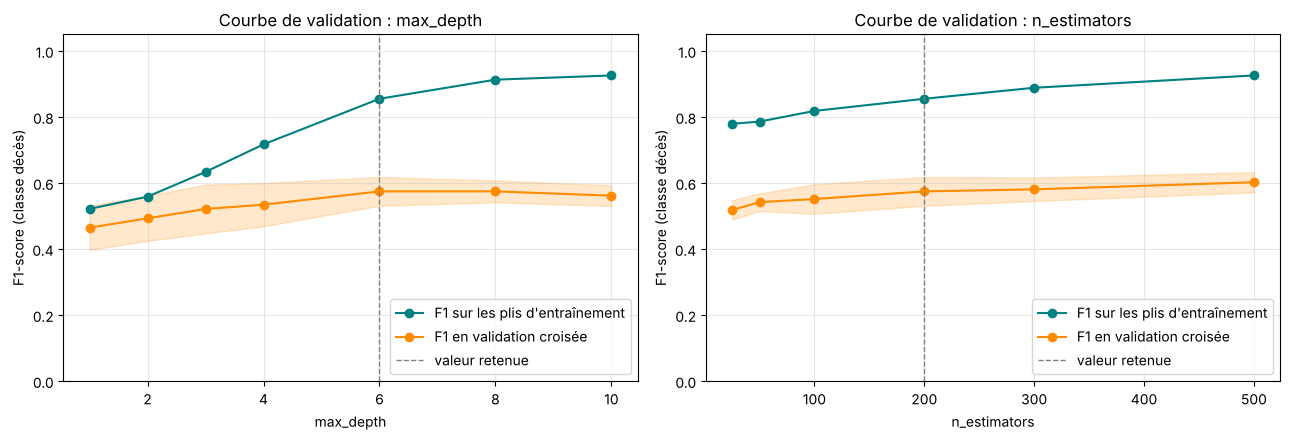

In [25]:
meilleur_xgb_adm = search_adm.best_estimator_

courbes = {
    "max_depth": [1, 2, 3, 4, 6, 8, 10],
    "n_estimators": [25, 50, 100, 200, 300, 500],
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (param, valeurs) in zip(axes, courbes.items()):
    f1_tr, f1_val = validation_curve(
        meilleur_xgb_adm, X_adm_train_imp, y_train,
        param_name=param, param_range=valeurs, cv=cv, scoring="f1", n_jobs=-1,
    )
    ax.plot(valeurs, f1_tr.mean(axis=1), "o-", color="teal", label="F1 sur les plis d'entraînement")
    ax.plot(valeurs, f1_val.mean(axis=1), "o-", color="darkorange", label="F1 en validation croisée")
    ax.fill_between(valeurs, f1_val.mean(axis=1) - f1_val.std(axis=1),
                    f1_val.mean(axis=1) + f1_val.std(axis=1), color="darkorange", alpha=0.2)
    ax.axvline(search_adm.best_params_[param], color="gray", linestyle="--", lw=1, label="valeur retenue")
    ax.set_xlabel(param); ax.set_ylabel("F1-score (classe décès)")
    ax.set_title(f"Courbe de validation : {param}")
    ax.set_ylim(0, 1.05); ax.grid(alpha=0.3); ax.legend(loc="lower right")
    meilleur = valeurs[int(np.argmax(f1_val.mean(axis=1)))]
    print(f"{param} : F1 validation max = {f1_val.mean(axis=1).max():.3f} pour {param} = {meilleur} | "
          f"F1 entraînement à la valeur max testée = {f1_tr.mean(axis=1)[-1]:.3f}")
plt.tight_layout()
plt.show()

**Interprétation.** 

- **`max_depth`** : le F1 d'entraînement monte de 0,52 (arbres à un seul niveau) à 0,93 (profondeur 10), alors que le F1 de validation plafonne vers 0,57-0,58 à partir d'une profondeur de 6, puis baisse légèrement (0,56 à une profondeur de 10). L'écart croissant entre les deux courbes est la signature du **surapprentissage** : au-delà d'une profondeur de 6, les arbres captent du bruit propre au train. À l'inverse, les arbres peu profonds (1 à 3) sous-apprennent avec ce pas d'apprentissage très faible.
- **`n_estimators`** : avec `learning_rate=0.01`, chaque arbre corrige très peu les erreurs ; le F1 de validation continue de progresser légèrement jusqu'à 500 arbres (0,60), au-delà de la valeur maximale de la grille (300). Cela illustre le lien entre les deux hyperparamètres : un petit pas d'apprentissage demande davantage d'arbres. La bande orangée (± un écart-type entre plis) montre toutefois que ces écarts restent du même ordre que la variabilité entre plis.

**Ce que nous ferions avec plus de temps de calcul.**
- augmenter `n_iter` (ou utiliser une recherche bayésienne, par exemple avec Optuna), car 20 combinaisons sur 1 296 laissent une part de hasard dans le résultat ;
- utiliser l'**arrêt précoce** (*early stopping*) sur un jeu de validation pour fixer automatiquement `n_estimators` ;
- régler aussi `reg_lambda`, `reg_alpha` et `gamma` ;
- optimiser une métrique indépendante du seuil (`average_precision` ou `roc_auc`) plutôt que le F1 au seuil 0,5, puisque le seuil est de toute façon choisi ensuite (partie VIII) ;
- utiliser une **validation croisée imbriquée** (*nested CV*) pour estimer la performance sans le léger biais optimiste dû au réglage sur les mêmes plis.

### VII.6 - Réglage du SVM

On entraîne maintenant un **SVM** (*Support Vector Machine*) pour le comparer à XGBoost. Un SVM est un **classifieur** qui sépare les deux classes par une frontière maximisant la **marge** : la distance entre la frontière et les patients les plus proches. La distance d'un patient à la frontière sert de score : plus un patient est du côté « décès » et loin de la frontière, plus il est jugé à risque.

**Données utilisées.** Le SVM calcule des distances entre patients : une variable à grande échelle (par exemple la pression en mmHg) écraserait les variables binaires. Il faut donc les **données standardisées** (`X_adm_train_sc`). XGBoost, basé sur des arbres, n'en a pas besoin.

**Espace de recherche.**

| Hyperparamètre | Valeurs testées | Effet |
|---|---|---|
| `C` | 0,1 ; 1 ; 10 ; 100 | pénalité des erreurs. `C` grand : marge étroite, risque de surapprentissage ; `C` petit : modèle plus simple |
| `kernel` | `rbf`, `linear`, `sigmoid` | forme de la frontière : courbe (`rbf`), droite (`linear`) ou variante (`sigmoid`) |
| `gamma` | `scale`, `auto`, 0,001 à 1 | portée d'influence d'un patient ; ignoré pour le noyau `linear`. `gamma` grand : frontière très locale, surapprentissage |
| `class_weight` | `balanced`, `None` | `balanced` pénalise davantage les erreurs sur les décès, pour compenser leur rareté |

Cet espace contient 4 × 6 × 3 × 2 = 144 combinaisons. Comme pour XGBoost, le Random Search en tire 20 et les évalue par validation croisée stratifiée (F1-score), sur le train uniquement.

Le SVM ne donne pas de probabilités directement : on utilisera sa **distance à la frontière** (`decision_function`) comme score. `probability=True` n'est donc pas utilisé : il ralentit fortement l'entraînement et n'est pas nécessaire ici.

In [26]:
# 1. Espace de recherche
svm_param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1],
    "kernel": ["rbf", "linear", "sigmoid"],
    "class_weight": ["balanced", None],
}

# 2. SVM de base (sans probability=True : on utilise decision_function)
svm_base = SVC(random_state=SEED)

# 3. Recherche des meilleurs hyperparamètres par validation croisée
search_svm = RandomizedSearchCV(
    estimator=svm_base,
    param_distributions=svm_param_grid,
    n_iter=20,
    cv=cv,
    scoring="f1",
    random_state=SEED,
    n_jobs=-1,
)

# Données standardisées (_sc) indispensables pour un SVM
search_svm.fit(X_adm_train_sc, y_train)
best_model_svm = search_svm.best_estimator_

print(f"Meilleur F1-score en CV pour le SVM : {search_svm.best_score_:.3f}")
print("Meilleurs hyperparamètres SVM :", search_svm.best_params_)
print(f"Pour comparaison, XGBoost réglé : {search_adm.best_score_:.3f}")

Meilleur F1-score en CV pour le SVM : 0.531
Meilleurs hyperparamètres SVM : {'kernel': 'rbf', 'gamma': 0.001, 'class_weight': 'balanced', 'C': 10}
Pour comparaison, XGBoost réglé : 0.575


**Interprétation.** Le meilleur SVM utilise un noyau gaussien (`rbf`) avec un `gamma` très faible (0,001), une pénalité `C = 10` et la pondération `balanced`. Un `gamma` aussi petit donne une frontière très lisse, proche d'une frontière linéaire, ce qui rejoint l'observation faite avec la régression logistique (VII.3). Son F1 en validation croisée (0,531) est inférieur à celui de XGBoost (0,575) : sur le train, XGBoost est déjà le meilleur des deux. Le choix entre les deux modèles repose donc sur la validation croisée ; le jeu de test servira à le confirmer.

## <a id="partie-VIII"></a>VIII - Évaluation sur le jeu de test (scénario Admission)

### VIII.1 - Choix du seuil de décision de XGBoost

XGBoost ne répond pas directement « décès » ou « survie » : il calcule une **probabilité de décès** pour chaque patient. La prédiction s'obtient en comparant cette probabilité à un **seuil**. Le seuil par défaut (0,5) n'est pas adapté à notre problème : en contexte médical, rater un décès (faux négatif) est bien plus grave qu'une fausse alerte (faux positif). On abaisse donc le seuil pour détecter plus de décès, au prix de plus de fausses alertes.

**Objectif fixé : un recall d'au moins 80 %** (détecter au moins 8 décès sur 10).

**Méthode.**
1. `cross_val_predict` calcule, pour chaque patient du train, une probabilité de décès prédite par un modèle qui **ne l'a pas vu à l'entraînement** (prédiction « hors pli »). Ces probabilités sont donc réalistes, ce qui n'est pas le cas si l'on prédit sur les données d'entraînement.
2. `precision_recall_curve` calcule, pour chaque seuil possible, le recall et la précision correspondants. Quand le seuil augmente, le recall diminue.
3. Parmi les seuils qui garantissent un recall ≥ 80 %, on retient le **plus élevé** : c'est celui qui génère le moins de fausses alertes pour ce niveau de recall.

**Précaution contre la fuite de données.** Le seuil est choisi **uniquement sur le train**. Le jeu de test n'intervient pas dans ce choix, il servira seulement à vérifier le résultat (VIII.2).

Seuil retenu pour un recall >= 80% : 0.370
Sur le train (validation croisée), la précision à ce seuil est de 37.7%


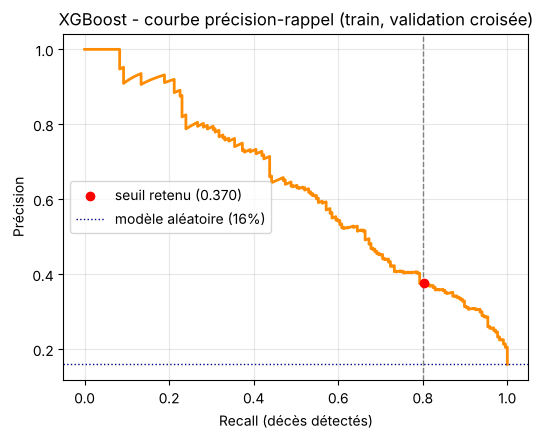

In [27]:
# Meilleur modèle trouvé par la recherche d'hyperparamètres
best_model_adm = search_adm.best_estimator_

# Probabilités de décès « hors pli » sur le train :
# chaque patient est prédit par un modèle qui ne l'a pas vu à l'entraînement
y_proba_train_cv = cross_val_predict(
    best_model_adm,
    X_adm_train_imp,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Courbe précision-rappel sur le train
precisions, recalls, thresholds = precision_recall_curve(y_train, y_proba_train_cv)

# Seuil le plus élevé qui garantit un recall >= 80 %
# (recalls décroît quand le seuil augmente : le dernier indice valide correspond au seuil le plus haut)
RECALL_CIBLE = 0.80
idx_rappel_cible = np.where(recalls[:-1] >= RECALL_CIBLE)[0]
assert len(idx_rappel_cible) > 0, f"Aucun seuil n'atteint un recall de {RECALL_CIBLE:.0%}"

seuil_medical = thresholds[idx_rappel_cible[-1]]
precision_au_seuil = precisions[idx_rappel_cible[-1]]
print(f"Seuil retenu pour un recall >= {RECALL_CIBLE:.0%} : {seuil_medical:.3f}")
print(f"Sur le train (validation croisée), la précision à ce seuil est de {precision_au_seuil:.1%}")

# Courbe précision-rappel avec le point retenu
plt.figure(figsize=(6, 4.5))
plt.plot(recalls, precisions, color="darkorange", lw=2)
plt.scatter([recalls[idx_rappel_cible[-1]]], [precision_au_seuil], color="red", zorder=3,
            label=f"seuil retenu ({seuil_medical:.3f})")
plt.axvline(RECALL_CIBLE, color="gray", linestyle="--", lw=1)
plt.axhline(y_train.mean(), color="navy", linestyle=":", lw=1, label=f"modèle aléatoire ({y_train.mean():.0%})")
plt.xlabel("Recall (décès détectés)")
plt.ylabel("Précision")
plt.title("XGBoost - courbe précision-rappel (train, validation croisée)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Interprétation.** Le seuil qui garantit un recall d'au moins 80 % sur le train est de 0,370, en dessous du seuil par défaut de 0,5. La valeur du seuil n'a pas de sens absolu : elle dépend de la façon dont le modèle répartit ses probabilités (un petit `learning_rate` les resserre). À ce seuil, la précision en validation croisée est de 37,7 % : un peu plus d'une alerte sur trois concerne un patient qui décédera réellement. C'est plus de deux fois mieux que le hasard (16 %, ligne pointillée), mais cela signifie qu'il faut accepter environ 1,7 fausse alerte pour chaque décès correctement détecté. Ce compromis est cohérent avec l'usage clinique visé : une alerte déclenche une surveillance renforcée, pas un traitement risqué.

### VIII.2 - Évaluation de XGBoost sur le jeu de test

C'est la **première utilisation du jeu de test** pour ce modèle. On applique le seuil choisi en VIII.1 aux probabilités prédites sur les patients de test, puis on lit la matrice de confusion :

|  | Prédit survie | Prédit décès |
|---|---|---|
| **Réellement survie** | vrais négatifs | **fausses alertes** (faux positifs) |
| **Réellement décès** | **décès manqués** (faux négatifs) | décès détectés (vrais positifs) |

Les deux cases en gras sont les erreurs. Les décès manqués sont les plus graves : c'est ce que le seuil cherche à limiter. Le rapport de classification donne ensuite, pour la classe « Décès » :
- le **recall** : part des décès réels détectés ;
- la **précision** : part des alertes qui concernent un vrai décès, c'est le prix à payer en fausses alertes ;
- le **F1-score** : compromis entre les deux.

Le recall obtenu sur le test devrait être proche de 80 %, mais pas identique : le seuil a été fixé sur le train, et le test ne contient que 54 décès (un décès de plus ou de moins change le recall d'environ 2 points).

===== XGBoost - Test, seuil à 0.370 =====
Matrice de confusion [[VN, FP], [FN, VP]] :
[[200  86]
 [  8  46]]
              precision    recall  f1-score   support

      Survie       0.96      0.70      0.81       286
       Décès       0.35      0.85      0.49        54

    accuracy                           0.72       340
   macro avg       0.66      0.78      0.65       340
weighted avg       0.86      0.72      0.76       340



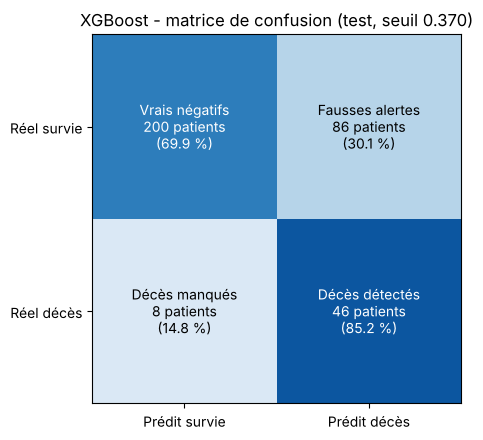

In [28]:
def tracer_matrice(ax, y_true, y_pred, titre):
    """Matrice de confusion en couleur : effectifs et % de chaque vraie classe."""
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100   # chaque ligne = 100 % de la vraie classe
    noms = [["Vrais négatifs", "Fausses alertes"], ["Décès manqués", "Décès détectés"]]
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            couleur = "white" if cm_pct[i, j] > 50 else "black"
            ax.text(j, i, f"{noms[i][j]}\n{cm[i, j]} patients\n({cm_pct[i, j]:.1f} %)",
                    ha="center", va="center", color=couleur, fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Prédit survie", "Prédit décès"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Réel survie", "Réel décès"])
    ax.set_title(titre)


# Application du seuil choisi sur le train aux patients de test
y_proba_test = best_model_adm.predict_proba(X_adm_test_imp)[:, 1]
y_pred_medical = (y_proba_test >= seuil_medical).astype(int)

print(f"===== XGBoost - Test, seuil à {seuil_medical:.3f} =====")
print("Matrice de confusion [[VN, FP], [FN, VP]] :")
print(confusion_matrix(y_test, y_pred_medical))
print(classification_report(y_test, y_pred_medical, target_names=["Survie", "Décès"]))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
tracer_matrice(ax, y_test, y_pred_medical, f"XGBoost - matrice de confusion (test, seuil {seuil_medical:.3f})")
plt.tight_layout()
plt.show()

**Interprétation.** Sur le jeu de test, le modèle détecte **46 décès sur 54 (recall de 85 %)** et en manque 8. Le recall dépasse l'objectif de 80 % fixé sur le train : le seuil se généralise correctement (l'écart de 5 points correspond à 2 ou 3 patients). En contrepartie, 86 survivants sur 286 (30 %) reçoivent une fausse alerte et la précision est de 35 %. L'*accuracy* (72 %) est inférieure à celle du modèle qui prédit toujours « survie » (84 %), ce qui confirme qu'elle n'est pas la bonne mesure ici : notre modèle accepte des erreurs sur les survivants pour rater beaucoup moins de décès.

### VIII.3 - Courbe ROC de XGBoost (scénario Admission)

La courbe ROC (*Receiver Operating Characteristic*) évalue la capacité du modèle à **classer** les patients : est-ce que ceux qui décèdent reçoivent une probabilité plus élevée que ceux qui survivent ? Contrairement à la matrice de confusion, elle ne dépend pas d'un seuil unique : elle les montre tous.

**Construction.** On fait varier le seuil de 1 à 0. À chaque valeur, on calcule deux taux sur le jeu de test :
- en ordonnée, le **taux de vrais positifs** (TPR, ou recall) : part des décès réels détectés ;
- en abscisse, le **taux de faux positifs** (FPR, ou 1 − spécificité) : part des survivants signalés à tort.

Abaisser le seuil détecte plus de décès (la courbe monte) mais génère plus de fausses alertes (la courbe va vers la droite).

**Comment la lire.**
- **La diagonale pointillée** correspond à un modèle aléatoire (AUC = 0,5) : il détecte autant de décès qu'il génère de fausses alertes.
- **Plus la courbe s'approche du coin supérieur gauche**, meilleur est le modèle : beaucoup de décès détectés pour peu de fausses alertes.
- **L'AUC** (aire sous la courbe) résume la courbe en un nombre. Elle s'interprète comme la probabilité qu'un patient décédé tiré au hasard reçoive une probabilité de décès plus élevée qu'un survivant tiré au hasard. Une AUC de 0,5 ne vaut rien, 1,0 est parfait. Au-dessus de 0,8, la discrimination est généralement jugée bonne.
- **Le point rouge** marque la position du modèle au **seuil médical** choisi en VIII.1 (recall visé de 80 %). Son ordonnée correspond au recall, son abscisse au taux de fausses alertes : c'est le coût du seuil, lisible directement sur la courbe.

**Pourquoi l'AUC en plus du recall.** Le recall et la précision dépendent du seuil, qui a été fixé par nous. L'AUC mesure la qualité du modèle indépendamment de ce choix, ce qui permet de comparer plus équitablement XGBoost et le SVM.

**Limite.** Le test contient seulement 54 décès : la courbe est en escalier et l'AUC a une incertitude de quelques points. Un écart de 0,01 ou 0,02 entre deux modèles n'est pas significatif.

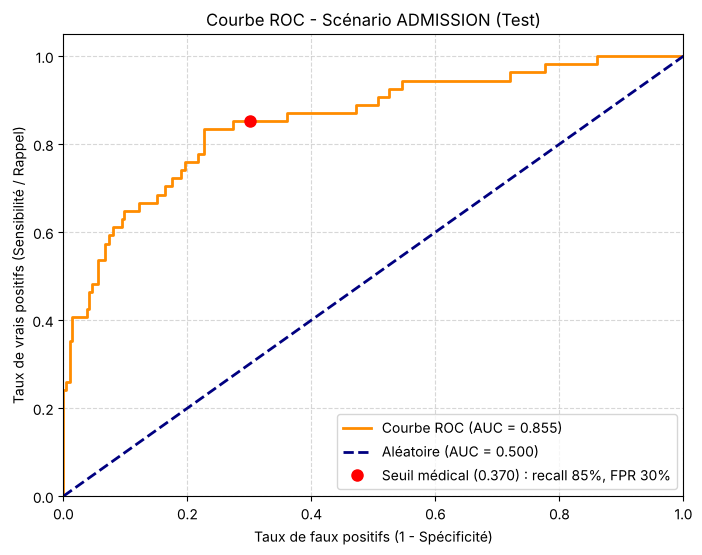

In [29]:
# 1. Taux de faux positifs (FPR) et de vrais positifs (TPR) pour tous les seuils (probabilités de VIII.2)
fpr, tpr, thresholds_roc = roc_curve(y_test, y_proba_test)
auc_score = roc_auc_score(y_test, y_proba_test)

# 2. Position exacte du modèle au seuil médical, calculée à partir de la matrice de confusion
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_medical).ravel()
fpr_seuil, tpr_seuil = fp / (fp + tn), tp / (tp + fn)

# 3. Tracer la courbe ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Courbe ROC (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Aléatoire (AUC = 0.500)')
plt.plot(fpr_seuil, tpr_seuil, 'ro', markersize=8,
         label=f'Seuil médical ({seuil_medical:.3f}) : recall {tpr_seuil:.0%}, FPR {fpr_seuil:.0%}')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taux de faux positifs (1 - Spécificité)")
plt.ylabel("Taux de vrais positifs (Sensibilité / Rappel)")
plt.title("Courbe ROC - Scénario ADMISSION (Test)")
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Interprétation.** L'AUC de XGBoost sur le test est de 0,855 : un patient décédé tiré au hasard reçoit une probabilité plus élevée qu'un survivant tiré au hasard dans environ 85 % des cas. C'est une bonne discrimination, cohérente avec l'AUC d'environ 0,87 mesurée pour XGBoost en validation croisée sur le train (VII.3). Le point rouge montre le coût du seuil médical : pour atteindre 85 % de recall, on accepte 30 % de faux positifs. La courbe monte rapidement au début (les patients les plus à risque sont bien repérés), puis plus lentement : les derniers décès à détecter ressemblent beaucoup à des survivants (partie X).

### VIII.4 - Seuil et évaluation du SVM

**Pour une comparaison équitable, on applique au SVM la même procédure que pour XGBoost :**
1. le score est la **distance à la frontière** (`decision_function`) ;
2. le seuil est choisi sur les scores de validation croisée du **train**, pour le même objectif de recall de 80 % ;
3. on évalue une seule fois sur le test.

Sans ces étapes, comparer le SVM au seuil par défaut avec XGBoost au seuil réglé pour 80 % de recall serait injuste : la différence de recall viendrait du seuil, pas du modèle. Le seuil du SVM est une distance, il peut donc être négatif : cela signifie que l'on classe « décès » des patients situés encore du côté « survie » de la frontière, pour détecter davantage de décès.

In [30]:
# 1. Seuil choisi sur les scores hors pli du TRAIN (même procédure que XGBoost)
scores_svm_train_cv = cross_val_predict(
    best_model_svm, X_adm_train_sc, y_train, cv=cv, method="decision_function"
)
precisions_svm, recalls_svm, thresholds_svm = precision_recall_curve(y_train, scores_svm_train_cv)
idx_svm = np.where(recalls_svm[:-1] >= RECALL_CIBLE)[0]
assert len(idx_svm) > 0, f"Aucun seuil n'atteint un recall de {RECALL_CIBLE:.0%}"
seuil_svm = thresholds_svm[idx_svm[-1]]
print(f"Seuil SVM retenu pour un recall >= {RECALL_CIBLE:.0%} : {seuil_svm:.3f}")
print(f"Précision à ce seuil sur le train (validation croisée) : {precisions_svm[idx_svm[-1]]:.1%}")

# 2. Évaluation unique sur le test
scores_svm_test = best_model_svm.decision_function(X_adm_test_sc)
y_pred_svm = (scores_svm_test >= seuil_svm).astype(int)

print(f"\n===== SVM - Test, seuil à {seuil_svm:.3f} =====")
print(classification_report(y_test, y_pred_svm, target_names=["Survie", "Décès"]))

print(f"===== Rappel : XGBoost - Test, seuil à {seuil_medical:.3f} =====")
print(classification_report(y_test, y_pred_medical, target_names=["Survie", "Décès"]))

Seuil SVM retenu pour un recall >= 80% : -0.234
Précision à ce seuil sur le train (validation croisée) : 36.5%

===== SVM - Test, seuil à -0.234 =====
              precision    recall  f1-score   support

      Survie       0.93      0.71      0.80       286
       Décès       0.32      0.72      0.44        54

    accuracy                           0.71       340
   macro avg       0.62      0.71      0.62       340
weighted avg       0.83      0.71      0.75       340

===== Rappel : XGBoost - Test, seuil à 0.370 =====
              precision    recall  f1-score   support

      Survie       0.96      0.70      0.81       286
       Décès       0.35      0.85      0.49        54

    accuracy                           0.72       340
   macro avg       0.66      0.78      0.65       340
weighted avg       0.86      0.72      0.76       340



### VIII.5 - Matrices de confusion : XGBoost contre SVM

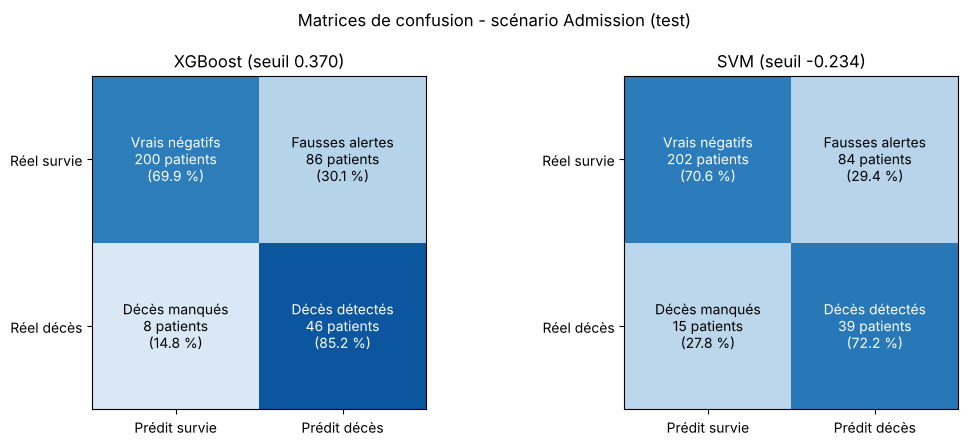

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
tracer_matrice(axes[0], y_test, y_pred_medical, f"XGBoost (seuil {seuil_medical:.3f})")
tracer_matrice(axes[1], y_test, y_pred_svm, f"SVM (seuil {seuil_svm:.3f})")
plt.suptitle("Matrices de confusion - scénario Admission (test)")
plt.tight_layout()
plt.show()

### VIII.6 - Comparaison des courbes ROC : XGBoost contre SVM

On superpose les courbes ROC des deux modèles sur le **même jeu de test**, pour comparer leur capacité à classer les patients à risque, indépendamment du seuil de décision.

**Comment lire le graphique.**
- Chaque courbe montre, pour tous les seuils possibles, le compromis entre décès détectés (axe vertical) et fausses alertes (axe horizontal).
- **La courbe la plus haute et la plus proche du coin supérieur gauche** est celle du meilleur modèle : à taux de fausses alertes égal, elle détecte plus de décès.
- **L'AUC** (aire sous la courbe) résume ce classement en un nombre : 0,5 correspond au hasard (diagonale pointillée), 1 à un classement parfait.
- **Les points** marquent la position réelle de chaque modèle au seuil retenu pour un recall de 80 % (choisi sur le train). Comparer leur hauteur donne le recall obtenu sur le test, comparer leur position horizontale donne le coût en fausses alertes.

**Deux points d'attention.**
- Si les courbes se croisent, aucun modèle n'est meilleur partout : le choix dépend de la zone de fonctionnement voulue. Ici, la zone qui nous intéresse est celle à fort recall, en haut du graphique.
- Le test ne contient que 54 décès : un écart d'AUC de quelques centièmes n'est pas significatif, et les courbes en escalier se croisent facilement.

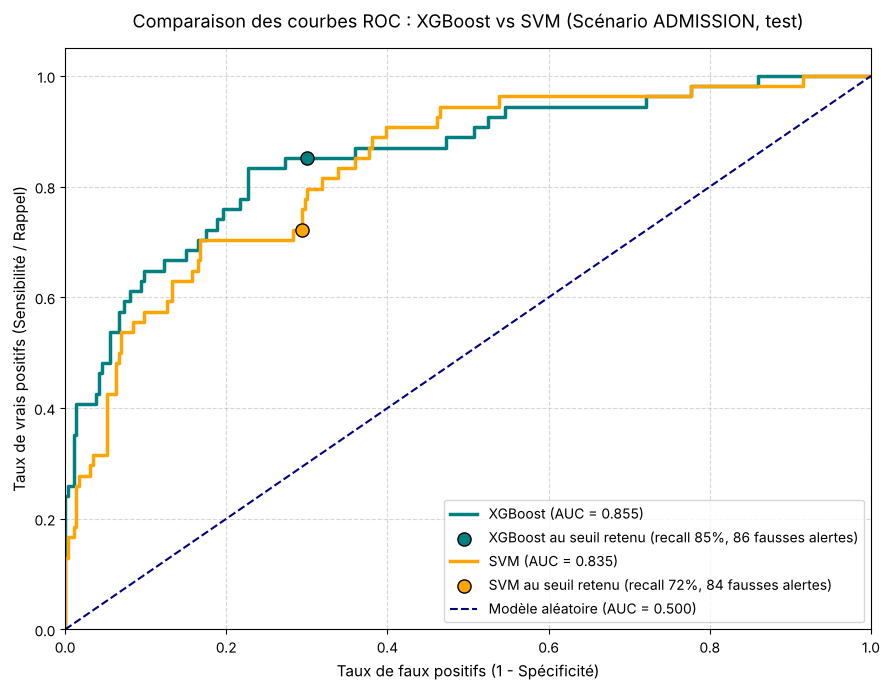

In [32]:
modeles = [
    ("XGBoost", y_proba_test,    y_pred_medical, "teal"),
    ("SVM",     scores_svm_test, y_pred_svm,     "orange"),
]

plt.figure(figsize=(9, 7))
for nom, scores, pred, couleur in modeles:
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)
    plt.plot(fpr, tpr, color=couleur, lw=2.5, label=f"{nom} (AUC = {auc:.3f})")

    # Position réelle du modèle au seuil retenu
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    plt.scatter([fp / (fp + tn)], [tp / (tp + fn)], color=couleur, edgecolor="black", s=90, zorder=3,
                label=f"{nom} au seuil retenu (recall {tp / (tp + fn):.0%}, {fp} fausses alertes)")

plt.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Modèle aléatoire (AUC = 0.500)")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taux de faux positifs (1 - Spécificité)", fontsize=11)
plt.ylabel("Taux de vrais positifs (Sensibilité / Rappel)", fontsize=11)
plt.title("Comparaison des courbes ROC : XGBoost vs SVM (Scénario ADMISSION, test)", fontsize=13, pad=15)
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### VIII.7 - Analyse comparative : XGBoost contre SVM (scénario Admission)

En analysant les courbes ROC et les rapports de classification des deux modèles, plusieurs conclusions s'imposent :

#### 1. Performance globale (AUC)
* **XGBoost (AUC = 0,855)** devance le **SVM (AUC = 0,835)**. L'écart (0,02) est faible et, avec 54 décès dans le test, il n'est pas significatif à lui seul ; il va cependant dans le même sens que la validation croisée sur le train (F1 de 0,575 pour XGBoost contre 0,531 pour le SVM).
* Les deux courbes se croisent : le SVM passe légèrement au-dessus pour des taux de fausses alertes de 40 à 60 %, mais XGBoost domine dans la zone qui nous intéresse (recall de 80 à 85 % pour 25 à 35 % de fausses alertes).

#### 2. Analyse clinique et gestion du risque (recall)
L'objectif médical crucial est de **détecter le maximum de patients à risque de décès** (minimiser les faux négatifs) :
* **XGBoost** (seuil de 0,370) atteint un **recall de 85 %** pour la classe « Décès » (46 décès détectés sur 54), avec une précision de **35 %**.
* **Le SVM** (noyau `rbf`, pondération `balanced`, seuil de −0,234) n'atteint qu'un **recall de 72 %** (39 décès détectés sur 54), avec une précision de **32 %**. Bien que son seuil ait été réglé sur le train pour 80 % de recall, il se généralise moins bien sur le test.

#### 3. Fausses alertes (spécificité)
* Les deux modèles génèrent un nombre comparable de **fausses alertes** : 86 pour XGBoost et 84 pour le SVM.
* À fausses alertes presque égales, **XGBoost manque 8 décès contre 15 pour le SVM**.

#### Conclusion
Pour le scénario Admission, **XGBoost est le modèle à privilégier** : il détecte 7 décès de plus que le SVM pour un nombre de fausses alertes équivalent, il est meilleur en validation croisée, et sa structure d'arbres le dispense de la standardisation des données. C'est donc lui que nous utilisons pour le scénario Jour 3.

## <a id="partie-IX"></a>IX - Scénario Jour 3 : apport des données des 3 premiers jours de soins

Jusqu'ici, le modèle ne connaissait que ce qui est disponible **à l'admission**. On répond maintenant à notre deuxième question : *les informations recueillies pendant les 3 premiers jours d'hospitalisation améliorent-elles la prédiction du décès ?* (hypothèse H2).

### IX.1 - Réglage de XGBoost sur les variables du Jour 3

**Ce qui change : uniquement les données.** `X_j3_train_imp` contient les mêmes patients que `X_adm_train_imp`, avec en plus les variables des 3 premiers jours : la récidive de douleur (`R_AB_*`), les opioïdes et anti-inflammatoires en soins intensifs (`NA_R_*`, `NOT_NA_*`) et les autres traitements du séjour (`NITR_S`, `LID_S_n`, `B_BLOK_S_n`…). La cellule affiche la liste exacte. Ces variables n'existent pas (ou pas de façon certaine) au jour 0 ; les utiliser pour une prédiction à l'admission serait de la fuite de données.

**Ce qui reste identique.** Pour que la différence de performance vienne bien des données et non d'un traitement de faveur, on garde exactement :
- le même modèle de base (`XGBClassifier` avec `scale_pos_weight` calculé sur le train) ;
- la même grille d'hyperparamètres et le même nombre de combinaisons testées (20) ;
- les mêmes 5 plis de validation croisée stratifiée (même `SEED`), et le même score d'optimisation (F1) ;
- les mêmes patients dans le train et dans le test.

**Lecture du résultat.** Comparer le meilleur F1 en validation croisée à celui du scénario Admission donne un premier indice de l'apport des 3 jours de soins. Cet indice reste provisoire : la comparaison définitive se fait sur le jeu de test, avec le même objectif de recall (80 %), en IX.3.

In [33]:
variables_j3_en_plus = [c for c in X_j3_train_imp.columns if c not in X_adm_train_imp.columns]
print(f"Variables disponibles à J3 mais pas à l'admission ({len(variables_j3_en_plus)}) : {variables_j3_en_plus}\n")

# Modèle de base pour J3 (mêmes réglages de départ que pour l'Admission)
xgb_j3 = XGBClassifier(
    scale_pos_weight=ratio_classes,
    eval_metric="logloss",
    random_state=SEED
)

# Recherche d'hyperparamètres sur le jeu J3 (même grille, même cv)
search_j3 = RandomizedSearchCV(
    estimator=xgb_j3,
    param_distributions=param_grid,
    n_iter=20,
    cv=cv,
    scoring="f1",
    random_state=SEED,
    n_jobs=-1
)

search_j3.fit(X_j3_train_imp, y_train)
best_model_j3 = search_j3.best_estimator_

print(f"Meilleur F1-score en CV (Jour 3) : {search_j3.best_score_:.3f}")
print(f"Pour comparaison, scénario Admission : {search_adm.best_score_:.3f}")
print("Meilleurs hyperparamètres (Jour 3) :", search_j3.best_params_)

Variables disponibles à J3 mais pas à l'admission (17) : ['R_AB_1_n', 'R_AB_2_n', 'R_AB_3_n', 'NITR_S', 'NA_R_1_n', 'NA_R_2_n', 'NA_R_3_n', 'NOT_NA_1_n', 'NOT_NA_2_n', 'NOT_NA_3_n', 'LID_S_n', 'B_BLOK_S_n', 'ANT_CA_S_n', 'GEPAR_S_n', 'ASP_S_n', 'TIKL_S_n', 'TRENT_S_n']

Meilleur F1-score en CV (Jour 3) : 0.638
Pour comparaison, scénario Admission : 0.575
Meilleurs hyperparamètres (Jour 3) : {'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


**Interprétation.** Les 17 variables supplémentaires du jour 3 sont bien celles attendues (douleur récurrente, opioïdes et anti-inflammatoires des 3 premiers jours, traitements en soins intensifs). En validation croisée, le F1 passe de 0,575 (Admission) à 0,638 (Jour 3), soit un gain de 0,06, supérieur à la variabilité entre plis (environ 0,04) : c'est un premier indice en faveur de H2. Le modèle retenu est aussi plus simple (arbres de profondeur 3, `learning_rate=0.1`, 300 arbres).

### IX.2 - Seuil de décision et évaluation du modèle Jour 3

On applique au modèle du Jour 3 **la même procédure** qu'au scénario Admission (VIII.1 et VIII.2), pour que les deux scénarios soient comparables :

1. **Probabilités hors pli sur le train.** `cross_val_predict` donne à chaque patient du train une probabilité de décès prédite par un modèle qui ne l'a pas vu à l'entraînement.
2. **Seuil pour un recall d'au moins 80 %.** On retient, sur ces probabilités, le seuil le plus élevé qui détecte au moins 80 % des décès : c'est celui qui génère le moins de fausses alertes pour ce niveau de recall.
3. **Évaluation unique sur le test.** Ce seuil est appliqué aux patients de test, jamais utilisés pour le choisir.

**Le seuil est recalculé pour le Jour 3.** On ne réutilise pas celui de l'Admission : un modèle différent, entraîné sur d'autres variables, produit des probabilités distribuées différemment, donc la valeur du seuil n'est pas transférable. Fixer le même *objectif de recall* (80 %) est ce qui rend les deux scénarios comparables, pas la valeur du seuil.

Seuil retenu pour J3 (recall >= 80%) : 0.160
Précision à ce seuil sur le train (validation croisée) : 40.9%
Pour comparaison, Admission : 37.7%

===== XGBoost Jour 3 - Test, seuil à 0.160 =====
              precision    recall  f1-score   support

      Survie       0.96      0.74      0.84       286
       Décès       0.38      0.85      0.53        54

    accuracy                           0.76       340
   macro avg       0.67      0.80      0.68       340
weighted avg       0.87      0.76      0.79       340

Matrice de confusion [[VN, FP], [FN, VP]] :
[[212  74]
 [  8  46]]


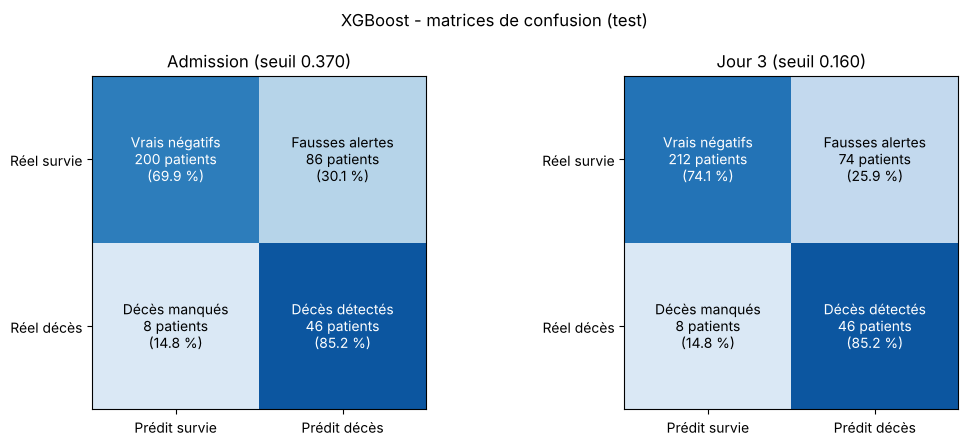

In [34]:
# Probabilités hors pli sur le TRAIN pour le modèle Jour 3
y_proba_j3_cv = cross_val_predict(
    best_model_j3,
    X_j3_train_imp,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Seuil le plus élevé qui garantit le même recall cible que pour l'Admission
precisions_j3, recalls_j3, thresholds_j3 = precision_recall_curve(y_train, y_proba_j3_cv)
idx_rappel_cible_j3 = np.where(recalls_j3[:-1] >= RECALL_CIBLE)[0]
assert len(idx_rappel_cible_j3) > 0, f"Aucun seuil n'atteint un recall de {RECALL_CIBLE:.0%} à J3"

seuil_medical_j3 = thresholds_j3[idx_rappel_cible_j3[-1]]
print(f"Seuil retenu pour J3 (recall >= {RECALL_CIBLE:.0%}) : {seuil_medical_j3:.3f}")
print(f"Précision à ce seuil sur le train (validation croisée) : {precisions_j3[idx_rappel_cible_j3[-1]]:.1%}")
print(f"Pour comparaison, Admission : {precision_au_seuil:.1%}")

# Évaluation unique sur le test J3
y_proba_test_j3 = best_model_j3.predict_proba(X_j3_test_imp)[:, 1]
y_pred_medical_j3 = (y_proba_test_j3 >= seuil_medical_j3).astype(int)

print(f"\n===== XGBoost Jour 3 - Test, seuil à {seuil_medical_j3:.3f} =====")
print(classification_report(y_test, y_pred_medical_j3, target_names=["Survie", "Décès"]))
print("Matrice de confusion [[VN, FP], [FN, VP]] :")
print(confusion_matrix(y_test, y_pred_medical_j3))

# Comparaison visuelle Admission / Jour 3
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
tracer_matrice(axes[0], y_test, y_pred_medical, f"Admission (seuil {seuil_medical:.3f})")
tracer_matrice(axes[1], y_test, y_pred_medical_j3, f"Jour 3 (seuil {seuil_medical_j3:.3f})")
plt.suptitle("XGBoost - matrices de confusion (test)")
plt.tight_layout()
plt.show()

### IX.3 - Comparaison finale : Admission contre Jour 3

C'est l'étape qui répond à la question posée dès l'introduction : **les informations recueillies pendant les 3 premiers jours améliorent-elles la prédiction du décès ?** (hypothèse H2). On compare les deux modèles XGBoost sur les **mêmes patients de test**, chacun avec son propre seuil, fixé sur le train pour viser 80 % de recall.

**Ce que fait la cellule.**
1. **Probabilités de décès** sur le test, pour chaque modèle (calculées en VIII.2 et IX.2).
2. **Tableau comparatif** : AUC, sensibilité, spécificité, décès manqués et fausses alertes.
3. **Deux graphiques** : courbes ROC et courbes précision-rappel.

**Lecture du tableau.**

| Métrique | Signification | Sens de la lecture |
|---|---|---|
| AUC | capacité à classer les patients à risque au-dessus des autres, tous seuils confondus | plus c'est haut, mieux c'est |
| Sensibilité (recall) | part des décès détectés | doit être proche de 80 % pour les deux modèles : la comparaison porte donc sur les lignes suivantes |
| Spécificité | part des survivants correctement identifiés | plus c'est haut, moins il y a de fausses alertes |
| Faux négatifs | décès non détectés, sur le total de décès du test | le plus grave : à minimiser |
| Faux positifs | survivants signalés à tort | le coût en surveillance inutile |

À recall comparable, **le meilleur modèle est celui qui a le moins de fausses alertes** (spécificité plus élevée).

**Lecture des courbes.**
- **ROC** : la courbe la plus proche du coin supérieur gauche est la meilleure.
- **Précision-rappel** : cette courbe est particulièrement adaptée aux classes déséquilibrées. À recall donné, une courbe plus haute signifie moins de fausses alertes. Un modèle aléatoire se situerait à la hauteur de la proportion de décès (environ 16 %).

**Précautions.** Le test ne contient que 54 décès : un décès de plus ou de moins déplace le recall d'environ 2 points, et un écart d'AUC de quelques centièmes n'est pas significatif. Pour conclure sur H2, on cherche un écart **net et cohérent** entre l'AUC, la précision-rappel et le nombre de fausses alertes, confirmé par la validation croisée sur le train.

=== COMPARAISON DES PERFORMANCES : ADMISSION vs JOUR 3 ===


,Admission (J0),Jour 3 (J3)
Métrique,,
F1 en validation croisée (train),0.575,0.638
AUC (Aire sous la courbe),0.855,0.891
Sensibilité (Rappel),85.2%,85.2%
Spécificité,69.9%,74.1%
Faux Négatifs (Décès ratés),8 / 54,8 / 54
Faux Positifs (Fausses alertes),86,74


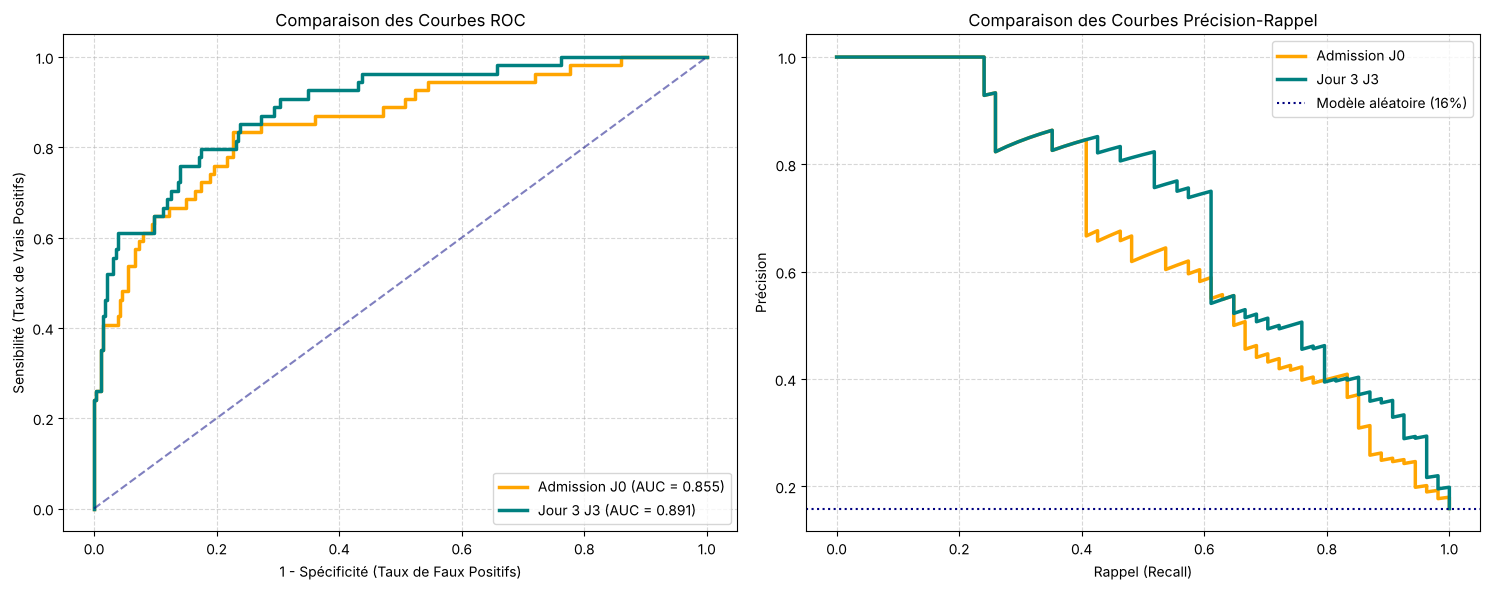

In [35]:
# 1. Probabilités de test des deux modèles (calculées en VIII.2 et IX.2 sur les mêmes colonnes qu'au fit)
y_proba_test_j0 = y_proba_test           # Admission
y_pred_j0, y_pred_j3 = y_pred_medical, y_pred_medical_j3

# 2. Métriques détaillées
cm_j0 = confusion_matrix(y_test, y_pred_j0)
cm_j3 = confusion_matrix(y_test, y_pred_j3)

# Spécificité : VN / (VN + FP) ; sensibilité (recall) : VP / (VP + FN)
spec_j0 = cm_j0[0, 0] / (cm_j0[0, 0] + cm_j0[0, 1])
spec_j3 = cm_j3[0, 0] / (cm_j3[0, 0] + cm_j3[0, 1])
sens_j0 = cm_j0[1, 1] / (cm_j0[1, 1] + cm_j0[1, 0])
sens_j3 = cm_j3[1, 1] / (cm_j3[1, 1] + cm_j3[1, 0])
auc_j0 = roc_auc_score(y_test, y_proba_test_j0)
auc_j3 = roc_auc_score(y_test, y_proba_test_j3)

perf_df = pd.DataFrame({
    'Métrique': ['F1 en validation croisée (train)', 'AUC (Aire sous la courbe)', 'Sensibilité (Rappel)',
                 'Spécificité', 'Faux Négatifs (Décès ratés)', 'Faux Positifs (Fausses alertes)'],
    'Admission (J0)': [
        f"{search_adm.best_score_:.3f}",
        f"{auc_j0:.3f}",
        f"{sens_j0:.1%}",
        f"{spec_j0:.1%}",
        f"{cm_j0[1, 0]} / {y_test.sum()}",
        f"{cm_j0[0, 1]}"
    ],
    'Jour 3 (J3)': [
        f"{search_j3.best_score_:.3f}",
        f"{auc_j3:.3f}",
        f"{sens_j3:.1%}",
        f"{spec_j3:.1%}",
        f"{cm_j3[1, 0]} / {y_test.sum()}",
        f"{cm_j3[0, 1]}"
    ]
}).set_index('Métrique')

print("=== COMPARAISON DES PERFORMANCES : ADMISSION vs JOUR 3 ===")
display(perf_df)

# 3. Tracé des courbes de comparaison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Courbe ROC
fpr_j0, tpr_j0, _ = roc_curve(y_test, y_proba_test_j0)
fpr_j3, tpr_j3, _ = roc_curve(y_test, y_proba_test_j3)

ax1.plot(fpr_j0, tpr_j0, color='orange', lw=2.5, label=f'Admission J0 (AUC = {auc_j0:.3f})')
ax1.plot(fpr_j3, tpr_j3, color='teal', lw=2.5, label=f'Jour 3 J3 (AUC = {auc_j3:.3f})')
ax1.plot([0, 1], [0, 1], color='navy', linestyle='--', alpha=0.5)
ax1.set_xlabel('1 - Spécificité (Taux de Faux Positifs)')
ax1.set_ylabel('Sensibilité (Taux de Vrais Positifs)')
ax1.set_title('Comparaison des Courbes ROC')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.5)

# Courbe Précision-Rappel
prec_j0, rec_j0, _ = precision_recall_curve(y_test, y_proba_test_j0)
prec_j3, rec_j3, _ = precision_recall_curve(y_test, y_proba_test_j3)

ax2.plot(rec_j0, prec_j0, color='orange', lw=2.5, label='Admission J0')
ax2.plot(rec_j3, prec_j3, color='teal', lw=2.5, label='Jour 3 J3')
ax2.axhline(y_test.mean(), color='navy', linestyle=':', label=f'Modèle aléatoire ({y_test.mean():.0%})')
ax2.set_xlabel('Rappel (Recall)')
ax2.set_ylabel('Précision')
ax2.set_title('Comparaison des Courbes Précision-Rappel')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Interprétation et réponse à H2.** 

- **Recall identique, moins de fausses alertes.** Les deux modèles détectent 46 décès sur 54 (recall de 85,2 %, 8 décès manqués chacun). À recall égal, le modèle Jour 3 génère **12 fausses alertes de moins** (74 contre 86), soit une spécificité de 74,1 % contre 69,9 %.
- **Meilleur classement.** L'AUC passe de 0,855 à 0,891. La courbe précision-rappel du Jour 3 est au-dessus de celle de l'Admission sur la plus grande partie des niveaux de recall (surtout entre 40 et 60 %) ; autour de 80 % de recall, notre zone de fonctionnement, les deux courbes sont proches.
- **Cohérence.** Le gain est observé à la fois en validation croisée sur le train (F1 de 0,575 à 0,638) et sur le test (AUC, fausses alertes) : il ne s'agit pas seulement d'un hasard du découpage.

**Réponse à H2 : hypothèse confirmée, avec un gain modeste.** Les informations des 3 premiers jours améliorent la prédiction surtout en réduisant les fausses alertes, pas en détectant davantage de décès. Ce gain doit être relativisé :
1. le test ne contient que 54 décès, et un écart d'AUC de 0,04 reste proche de la marge d'incertitude ;
2. une partie de l'information ajoutée correspond à des **décisions thérapeutiques** (opioïdes dans les premières heures `NA_R_1_n`, nitrates `NITR_S`, voir IX.4), qui reflètent en partie le jugement des médecins sur la gravité du patient. Dans la version précédente de ce notebook, où `NITR_S` était classée à tort parmi les traitements d'urgence et utilisée dès l'admission, les deux scénarios obtenaient des AUC équivalentes (environ 0,88). L'écart entre les scénarios tient donc en grande partie à ces traitements en soins intensifs, dont le moment exact devrait être vérifié avec les cliniciens.

### IX.4 - Comparaison de l'importance des variables : Admission contre Jour 3

Pour comprendre ce que les modèles ont appris, nous comparons l'importance relative des variables entre le modèle **Admission** et le modèle **Jour 3**. L'importance utilisée par XGBoost (`feature_importances_`, type *gain*) mesure l'amélioration moyenne de la fonction de perte apportée par les découpages qui utilisent cette variable. Une variable absente d'un scénario a une importance nulle dans ce scénario.

Deux précautions de lecture : l'importance indique ce qui **aide le modèle à prédire**, pas une relation de cause à effet ; et deux variables très corrélées (III.3) peuvent se partager l'importance.

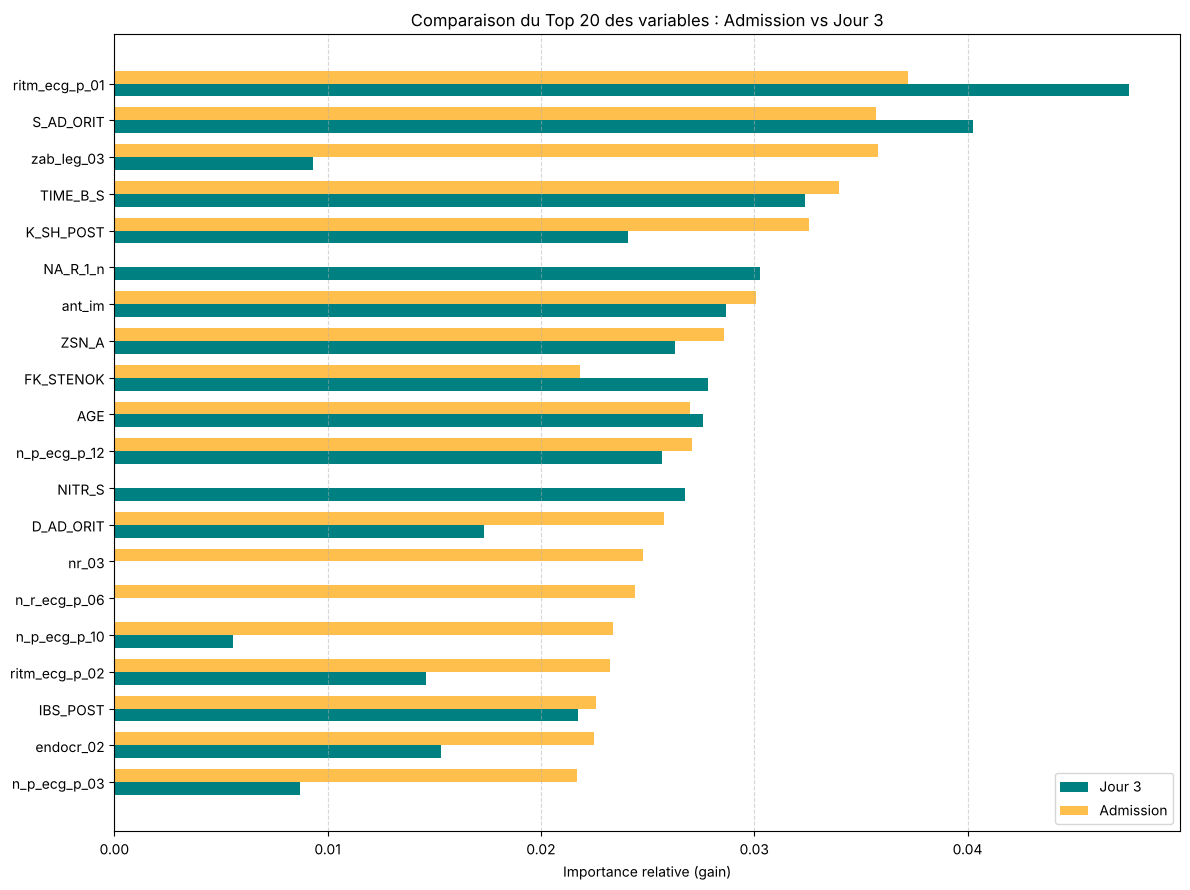

=== Les 10 variables les plus importantes à l'Admission ===


,Importance_Admission
Variable,
ritm_ecg_p_01,0.0372
zab_leg_03,0.0358
S_AD_ORIT,0.0357
TIME_B_S,0.0340
K_SH_POST,0.0325
ant_im,0.0301
ZSN_A,0.0286
n_p_ecg_p_12,0.0271
AGE,0.0270


=== Les 10 variables les plus importantes à Jour 3 ===


,Importance_Jour3,Importance_Admission
Variable,,
ritm_ecg_p_01,0.0476,0.0372
S_AD_ORIT,0.0402,0.0357
TIME_B_S,0.0324,0.0340
NA_R_1_n,0.0303,0.0000
ant_im,0.0287,0.0301
FK_STENOK,0.0278,0.0218
AGE,0.0276,0.0270
NITR_S,0.0268,0.0000
ZSN_A,0.0263,0.0286


=== Rang des variables créées par feature engineering (1 = la plus importante) ===


,rang Admission (sur 92),rang Jour 3 (sur 109)
Variable,,
PRESSION_PULSEE,23,18
RATIO_AST_ALT,42,44
NB_TRAITEMENTS_URGENCES,36,15


In [36]:
# 1. Importances des deux modèles (noms de colonnes = ceux des données utilisées pour le fit)
importances_adm = pd.DataFrame({
    'Variable': X_adm_train_imp.columns,
    'Importance_Admission': best_model_adm.feature_importances_
})
importances_j3 = pd.DataFrame({
    'Variable': X_j3_train_imp.columns,
    'Importance_Jour3': best_model_j3.feature_importances_
})

# 2. Fusion des deux tableaux pour la comparaison
comp_imp = pd.merge(importances_j3, importances_adm, on='Variable', how='left')
comp_imp['Importance_Admission'] = comp_imp['Importance_Admission'].fillna(0.0)  # variables J3 absentes à l'admission

# 3. Variables les plus importantes dans au moins un des deux scénarios
comp_imp['Max_Importance'] = comp_imp[['Importance_Jour3', 'Importance_Admission']].max(axis=1)
comp_top = comp_imp.sort_values(by='Max_Importance', ascending=False).head(20)

# 4. Graphique comparatif
fig, ax = plt.subplots(figsize=(12, 9))

y_pos = np.arange(len(comp_top))
width = 0.35

ax.barh(y_pos + width/2, comp_top['Importance_Jour3'], width, label='Jour 3', color='teal')
ax.barh(y_pos - width/2, comp_top['Importance_Admission'], width, label='Admission', color='orange', alpha=0.7)

ax.set_yticks(y_pos)
ax.set_yticklabels(comp_top['Variable'])
ax.invert_yaxis()  # Les plus importantes en haut
ax.set_xlabel('Importance relative (gain)')
ax.set_title('Comparaison du Top 20 des variables : Admission vs Jour 3')
ax.legend(loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 5. Tableaux : variables clés dans chaque scénario et place des variables créées en partie IV
print("=== Les 10 variables les plus importantes à l'Admission ===")
display(importances_adm.sort_values(by='Importance_Admission', ascending=False).head(10).set_index('Variable').round(4))
print("=== Les 10 variables les plus importantes à Jour 3 ===")
display(comp_imp.sort_values(by='Importance_Jour3', ascending=False).head(10)[['Variable', 'Importance_Jour3', 'Importance_Admission']].set_index('Variable').round(4))

rang_adm = importances_adm.set_index('Variable')['Importance_Admission'].rank(ascending=False).astype(int)
rang_j3 = importances_j3.set_index('Variable')['Importance_Jour3'].rank(ascending=False).astype(int)
print("=== Rang des variables créées par feature engineering (1 = la plus importante) ===")
display(pd.DataFrame({f"rang Admission (sur {len(rang_adm)})": rang_adm[NOUVELLES_VARIABLES],
                      f"rang Jour 3 (sur {len(rang_j3)})": rang_j3[NOUVELLES_VARIABLES]}))

**Interprétation.** 

- **Des importances réparties.** Aucune variable ne domine : la plus importante représente moins de 5 % du gain total. Le modèle combine de nombreux signaux faibles, ce qui confirme l'analyse des corrélations (III.3) : le risque de décès n'est pas porté par une seule mesure.
- **Un socle commun aux deux scénarios.** Les variables les plus utiles sont en grande partie les mêmes à l'admission et au jour 3, et elles ont un sens clinique clair : le rythme cardiaque à l'ECG d'admission (`ritm_ecg_p_01`, rythme sinusal normal), la pression systolique en soins intensifs (`S_AD_ORIT`), le délai d'arrivée à l'hôpital (`TIME_B_S`, avec le biais de survie vu en III.3), la localisation antérieure de l'infarctus (`ant_im`), l'insuffisance cardiaque chronique (`ZSN_A`), l'âge et le bloc de branche droit (`n_p_ecg_p_12`). Le choc cardiogénique (`K_SH_POST`), très lié au décès mais rare (37 patients du train), figure dans le top 10 à l'admission puis recule un peu à J3.
- **Ce qu'apporte le jour 3.** Deux variables propres au jour 3 entrent dans le top 10 : les **opioïdes en soins intensifs dans les premières heures** (`NA_R_1_n`), qui traduisent une douleur persistante, et les **nitrates liquides** (`NITR_S`), souvent utilisés en cas d'insuffisance cardiaque aiguë ou d'œdème pulmonaire. Ce sont des traitements, donc des indicateurs indirects de la gravité perçue par l'équipe médicale.
- **Variables créées en partie IV.** À J3, `NB_TRAITEMENTS_URGENCES` (15ᵉ sur 109) et `PRESSION_PULSEE` (18ᵉ) se classent dans le premier cinquième ; `RATIO_AST_ALT` reste au milieu du classement (44ᵉ). Le feature engineering apporte donc une contribution utile mais pas décisive.
- **Prudence.** L'importance de type *gain* peut surévaluer des variables rares : par exemple `zab_leg_03` (asthme dans les antécédents, 29 patients du train) figure parmi les plus importantes à l'admission, car quelques découpages sur ce petit groupe (38 % de décès) réduisent fortement l'erreur. Les valeurs SHAP ou l'importance par permutation permettraient de confirmer ce classement.

## <a id="partie-X"></a>X - Analyse clinique des faux négatifs (décès manqués à J3)

Même avec un seuil réglé pour détecter 80 % des décès, le modèle en laisse passer certains : ce sont les **faux négatifs**, des patients décédés que le modèle a jugés à faible risque. Ce sont les erreurs les plus graves. On les regarde de près pour comprendre ce qui les distingue des autres.

**Trois groupes sont comparés** parmi les patients de test :
- les **décès manqués** (faux négatifs) ;
- les **décès détectés** (vrais positifs) : des patients décédés que le modèle a bien repérés ;
- les **survivants**.

L'idée : si les décès manqués ressemblent plus aux survivants qu'aux décès détectés, le modèle ne dispose pas de variable qui les distingue. Ce sont des profils « atypiques ».

**Variables examinées.** Nous prenons huit variables cliniques majeures : l'âge (`AGE`), la pression systolique en soins intensifs (`S_AD_ORIT`), le choc cardiogénique à l'admission en soins intensifs (`K_SH_POST`), la fibrillation auriculaire persistante à l'ECG d'admission (`n_r_ecg_p_06`), le nombre de récidives de la douleur au jour 3 (`R_AB_3_n`, de 0 à 3), les leucocytes (`L_BLOOD`), les nitrates liquides en soins intensifs (`NITR_S`) et le stade d'insuffisance cardiaque chronique dans les antécédents (`ZSN_A`, de 0 à 4). On affiche d'abord le profil de chaque patient manqué, puis la **moyenne de chaque groupe**.

**Comment lire les moyennes.** Pour une variable continue (âge, pression, leucocytes), la moyenne est la valeur moyenne du groupe. Pour une variable binaire (0 ou 1), la moyenne est la **proportion** de patients du groupe qui présentent le signe. Pour une variable ordinale (`R_AB_3_n`, `ZSN_A`), c'est le niveau moyen. Les valeurs sont celles du jeu `X_j3_test_imp`, non standardisées, donc lisibles cliniquement ; les valeurs manquantes y ont été remplacées par la médiane ou le mode du train.

**Précaution.** Cette analyse porte sur le jeu de test et sur une dizaine de patients : elle sert à **comprendre** les erreurs, pas à modifier le modèle. Créer de nouvelles variables à partir de ces quelques cas reviendrait à ajuster le modèle au jeu de test (fuite de données et surapprentissage).

In [37]:
# Groupes de patients du test (selon la vraie issue et la prédiction au seuil retenu à J3)
mask_fn = (y_test == 1) & (y_pred_medical_j3 == 0)   # décès manqués (faux négatifs)
mask_vp = (y_test == 1) & (y_pred_medical_j3 == 1)   # décès détectés (vrais positifs)
mask_surv = (y_test == 0)                            # survivants

fn_patients   = X_j3_test_imp.loc[mask_fn[mask_fn].index]
vp_patients   = X_j3_test_imp.loc[mask_vp[mask_vp].index]
surv_patients = X_j3_test_imp.loc[mask_surv[mask_surv].index]

variables_analyse = [
    "AGE", "S_AD_ORIT", "K_SH_POST", "n_r_ecg_p_06",
    "R_AB_3_n", "L_BLOOD", "NITR_S", "ZSN_A",
]
assert all(v in X_j3_test_imp.columns for v in variables_analyse), "Variable absente de X_j3_test_imp"

print(f"--- Analyse des {len(fn_patients)} décès manqués (faux négatifs) à J3 ---\n")
fn_profil = fn_patients[variables_analyse].copy()
fn_profil["proba prédite"] = y_proba_test_j3[mask_fn.values].round(3)
fn_profil["cause du décès"] = df.loc[fn_profil.index, "LET_IS"].map(CAUSES_DECES)
display(fn_profil)

comparatif_df = pd.DataFrame({
    f"Décès manqués (n={len(fn_patients)})":  fn_patients[variables_analyse].mean(),
    f"Décès détectés (n={len(vp_patients)})": vp_patients[variables_analyse].mean(),
    f"Survivants (n={len(surv_patients)})":   surv_patients[variables_analyse].mean(),
})
display(comparatif_df.round(2))

# Causes de décès : manqués contre détectés
causes_groupes = pd.DataFrame({
    "manqués": df.loc[fn_patients.index, "LET_IS"].map(CAUSES_DECES).value_counts(),
    "détectés": df.loc[vp_patients.index, "LET_IS"].map(CAUSES_DECES).value_counts(),
}).fillna(0).astype(int)
print("Causes de décès des patients manqués et détectés :")
display(causes_groupes)

--- Analyse des 8 décès manqués (faux négatifs) à J3 ---



,AGE,S_AD_ORIT,K_SH_POST,n_r_ecg_p_06,R_AB_3_n,L_BLOOD,NITR_S,ZSN_A,proba prédite,cause du décès
ID,,,,,,,,,,
1486,58.0,130.0,0.0,0.0,0.0,14.9,0.0,0.0,0.008,Rupture myocardique
1574,70.0,150.0,0.0,1.0,0.0,6.2,1.0,0.0,0.061,Choc cardiogénique
1552,65.0,140.0,0.0,0.0,0.0,7.0,0.0,0.0,0.120,Choc cardiogénique
1492,82.0,120.0,0.0,0.0,0.0,7.6,1.0,1.0,0.144,Œdème pulmonaire
1538,62.0,120.0,0.0,0.0,0.0,8.0,0.0,0.0,0.086,Fibrillation ventriculaire
1430,56.0,140.0,0.0,0.0,0.0,6.0,1.0,0.0,0.017,Fibrillation ventriculaire
1499,55.0,220.0,0.0,0.0,0.0,12.1,0.0,1.0,0.059,Œdème pulmonaire
1627,75.0,100.0,0.0,0.0,0.0,5.7,0.0,0.0,0.112,Rupture myocardique


,Décès manqués (n=8),Décès détectés (n=46),Survivants (n=286)
AGE,65.38,68.41,61.80
S_AD_ORIT,140.00,116.52,136.94
K_SH_POST,0.00,0.17,0.00
n_r_ecg_p_06,0.12,0.07,0.01
R_AB_3_n,0.00,0.13,0.08
L_BLOOD,8.44,10.19,8.55
NITR_S,0.38,0.35,0.08
ZSN_A,0.25,0.24,0.13


Causes de décès des patients manqués et détectés :


,manqués,détectés
LET_IS,,
Aggravation de l'insuffisance cardiaque,0,5
Asystolie,0,6
Choc cardiogénique,2,19
Fibrillation ventriculaire,2,8
Rupture myocardique,2,7
Thromboembolie,0,1
Œdème pulmonaire,2,0


**Interprétation.** 

- **Des profils proches des survivants.** Les 8 décès manqués ressemblent davantage aux survivants qu'aux décès détectés : pression systolique normale (140 mmHg en moyenne, comme les survivants, contre 117 mmHg pour les décès détectés), aucun choc cardiogénique (contre 17 % des décès détectés), leucocytes normaux (8,4 contre 10,2), aucune récidive de douleur au jour 3. Leur âge moyen (65 ans) est intermédiaire. Le modèle leur attribue des probabilités de 0,008 à 0,144, toutes sous le seuil de 0,160 : trois d'entre eux (0,112 à 0,144) sont proches du seuil, les autres sont jugés nettement à faible risque.
- **Seul signal commun : les nitrates.** 3 décès manqués sur 8 ont reçu des nitrates liquides en soins intensifs, une proportion comparable à celle des décès détectés (35 %) et bien supérieure à celle des survivants (8 %). Ce signal isolé ne suffit pas à compenser l'absence des autres signes de gravité.
- **Des causes de décès brutales.** Les décès manqués se répartissent entre rupture myocardique (2), fibrillation ventriculaire (2), œdème pulmonaire (2) et choc cardiogénique (2). Les ruptures et les fibrillations ventriculaires sont des complications soudaines, qui peuvent survenir chez un patient jusque-là stable : il est attendu qu'un modèle fondé sur l'état à l'admission ou au jour 3 les anticipe mal.
- **Conséquence.** Ces patients sont « atypiques » au regard des variables disponibles : pour les détecter, il faudrait des informations absentes du jeu de données (biomarqueurs comme la troponine, échocardiographie, suivi continu de l'ECG) plutôt qu'un modèle plus complexe. Avec 8 patients, on ne peut pas en tirer de règle générale.

## <a id="partie-XI"></a>XI - Conclusion et perspectives

### XI.1 - Tableau récapitulatif des résultats

Le tableau ci-dessous rassemble, pour les trois modèles évalués sur le jeu de test, le score de validation croisée (train) et les métriques de test au seuil retenu (recall visé de 80 %).

In [38]:
def metriques_test(y_vrai, y_pred, scores):
    """Métriques de test au seuil retenu + AUC (indépendante du seuil)."""
    tn, fp, fn, tp = confusion_matrix(y_vrai, y_pred).ravel()
    return {"AUC": roc_auc_score(y_vrai, scores), "Recall": tp / (tp + fn), "Précision": tp / (tp + fp),
            "Spécificité": tn / (tn + fp), "Décès manqués (FN)": fn, "Fausses alertes (FP)": fp}

recap = pd.DataFrame({
    "XGBoost - Admission": {"F1 en CV (train)": search_adm.best_score_,
                            **metriques_test(y_test, y_pred_medical, y_proba_test)},
    "SVM - Admission":     {"F1 en CV (train)": search_svm.best_score_,
                            **metriques_test(y_test, y_pred_svm, scores_svm_test)},
    "XGBoost - Jour 3":    {"F1 en CV (train)": search_j3.best_score_,
                            **metriques_test(y_test, y_pred_medical_j3, y_proba_test_j3)},
}).T
recap[["Décès manqués (FN)", "Fausses alertes (FP)"]] = recap[["Décès manqués (FN)", "Fausses alertes (FP)"]].astype(int)
display(recap.round(3))

,F1 en CV (train),AUC,Recall,Précision,Spécificité,Décès manqués (FN),Fausses alertes (FP)
XGBoost - Admission,0.575,0.855,0.852,0.348,0.699,8,86
SVM - Admission,0.531,0.835,0.722,0.317,0.706,15,84
XGBoost - Jour 3,0.638,0.891,0.852,0.383,0.741,8,74


### XI.2 - Réponses à la problématique et aux hypothèses

> **Peut-on prédire le décès dès l'admission ?** Oui, en partie. Avec les seules informations disponibles à l'admission, XGBoost classe correctement les patients (AUC de 0,855 sur le test) et, avec un seuil réglé sur le train, détecte 46 décès sur 54 (recall de 85 %), au prix de fausses alertes pour environ 30 % des survivants.
>
> **Les 3 premiers jours améliorent-ils la prédiction ?** Oui, modestement : à recall égal, le modèle Jour 3 réduit les fausses alertes (74 contre 86) et améliore l'AUC (0,891).

| Hypothèse | Verdict | Arguments |
|---|---|---|
| **H1** : certaines variables diffèrent entre décédés et survivants et suffisent à prédire le risque | **Confirmée en partie** | l'âge, la pression artérielle, les leucocytes, le choc cardiogénique et le rythme cardiaque diffèrent nettement (III.2, III.3) ; mais aucune ne suffit seule : c'est leur combinaison par le modèle qui permet une AUC de 0,86 à 0,89 |
| **H2** : les variables du jour 3 améliorent la prédiction | **Confirmée, gain modeste** | F1 en validation croisée de 0,575 à 0,638, AUC de 0,855 à 0,891, 12 fausses alertes de moins à recall égal ; gain en partie porté par des traitements en soins intensifs (`NA_R_1_n`, `NITR_S`) |
| **H3** : il faut corriger le déséquilibre des classes | **Confirmée** | sans correction et au seuil 0,5, XGBoost ne détecte que 45 % des décès ; la pondération (`scale_pos_weight`) puis l'abaissement du seuil permettent d'atteindre 85 % |

### XI.3 - Ce que nous retenons de la démarche

- La **séparation stricte** entre admission et jour 3, et le calcul de toutes les transformations sur le train seul, évitent la fuite de données. Corriger le classement de `NITR_S` (traitement en soins intensifs, et non traitement d'urgence) a montré à quel point ce choix influence la comparaison des deux scénarios.
- Le **choix du seuil** de décision compte autant que le choix du modèle : c'est lui qui traduit l'objectif médical (« ne pas rater plus de 2 décès sur 10 ») en règle de décision.
- Le **réglage des hyperparamètres** apporte peu ici et le **surapprentissage** apparaît vite (F1 d'entraînement proche de 1) : avec 217 décès dans le train, c'est la quantité de données qui limite les performances, plus que la complexité du modèle.
- Un modèle **linéaire** (régression logistique) fait presque aussi bien que XGBoost en validation croisée : il pourrait être préféré en pratique pour sa transparence.
- L'**exploration non supervisée** retrouve sans la cible un axe de gravité (fibrillation auriculaire, âge, rythme) et un petit groupe de patients à haut risque, ce qui rejoint l'approche de l'article.

### XI.4 - Limites

- **Petit nombre de décès** : 217 dans le train et 54 dans le test. Chaque décès compte pour environ 2 points de recall, et des écarts d'AUC de quelques centièmes ne sont pas significatifs. Un intervalle de confiance par *bootstrap* permettrait de le quantifier.
- **Données anciennes et monocentriques** (Krasnoïarsk, 1992-1995) : les pratiques et les traitements ont changé depuis (angioplastie, dosage de la troponine) ; le modèle ne serait pas transposable tel quel à un hôpital actuel.
- **Imputation simple** (médiane / mode) : elle ignore les liens entre variables et efface l'information portée par le fait qu'une valeur soit manquante.
- **Variabilité des résultats** : la recherche aléatoire limitée à 20 combinaisons et l'aléa interne de XGBoost (`subsample`, `colsample_bytree`) font varier de quelques points les hyperparamètres retenus et les scores selon les versions des bibliothèques.

### XI.5 - Perspectives : comment nous poursuivrions

**1. Demander des informations aux cliniciens et aux auteurs du jeu de données**
- le **moment exact** des traitements en soins intensifs (`NITR_S`, `LID_S_n`…) : sont-ils donnés dès l'arrivée ou après une aggravation ? La réponse décide s'ils peuvent être utilisés dès l'admission ;
- la **signification des valeurs manquantes** : les traitements de l'équipe d'urgence manquent pour les mêmes 37 % de patients ; s'agit-il des patients qui n'ont pas été transportés par cette équipe ?
- les **unités** des enzymes (`ALT_BLOOD`, `AST_BLOOD`, `KFK_BLOOD`), dont les valeurs ne correspondent pas aux UI/L annoncées, et la signification des pressions notées 0 mmHg ;
- le **coût relatif** d'une fausse alerte et d'un décès manqué, pour fixer l'objectif de recall (80 %) sur une base médicale plutôt que par convention.

**2. Montrer des exemples aux médecins**
- présenter les profils des décès manqués (partie X) et des fausses alertes les plus nettes, pour savoir si un clinicien les aurait repérés et sur quels éléments ;
- expliquer chaque prédiction individuellement (valeurs SHAP) pour vérifier que le modèle s'appuie sur des raisonnements cliniquement plausibles.

**3. Méthodes alternatives à tester**
- la **gestion native des valeurs manquantes** par XGBoost (sans imputation), l'**imputation multiple** (MICE, KNN) et des **indicateurs de valeurs manquantes** ;
- une **régression logistique pénalisée** (L1/L2) comme modèle transparent, et la **calibration** des probabilités, pour donner au médecin un risque exprimé en pourcentage ;
- une **validation croisée imbriquée** et des intervalles de confiance par *bootstrap* ;
- d'autres cibles : **prédire la cause du décès** (classification multiclasse) ou d'autres complications (`OTEK_LANC`, `RAZRIV`…) ;
- une **analyse de survie**, si la date du décès était disponible ;
- la méthode de l'article (**arbres principaux élastiques**, ClinTrajan), pour positionner chaque patient sur une trajectoire clinique et utiliser ce « pseudo-temps » comme variable ;
- le **deep learning** ne serait envisageable qu'avec beaucoup plus de patients (par exemple un registre multicentrique).

**Une piste écartée.** Une version précédente du projet cherchait à créer de nouvelles variables à partir des décès manqués du **jeu de test**. Cette démarche a été abandonnée : concevoir des variables en regardant le test revient à ajuster le modèle au test (fuite de données), et le faire à partir de quelques patients mène au surapprentissage (le nombre de décès manqués avait d'ailleurs augmenté).